In [1]:
import os
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import geopandas as gpd
import osmnx as ox

from scipy.spatial import cKDTree
from scipy.stats import spearmanr

sns.set_theme(style="whitegrid")

print("All imports completed successfully.")
print("OSMnx version:", ox.__version__)

All imports completed successfully.
OSMnx version: 2.1.1


In [2]:
os.makedirs("../data/external", exist_ok=True)
os.makedirs("../reports/figures", exist_ok=True)

print("Required folders are ready.")

Required folders are ready.


In [3]:
ox.settings.use_cache = True
ox.settings.requests_timeout = 180

print("OSMnx cache enabled:", ox.settings.use_cache)
print("OSMnx request timeout:", ox.settings.requests_timeout)

OSMnx cache enabled: True
OSMnx request timeout: 180


In [4]:
df = pd.read_csv("../data/processed/clean_v2.csv")

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

Dataset shape: (7457, 18)

First five rows:


,prop_id,latitude,longitude,property_type,owntype,bedroom_num,bathroom_num,balcony_num,furnish,facing,age,floor_num,total_floor,total_landmark_count,area_sqft,area_is_carpet,locality_grouped,price_lakhs
0,O71585872,28.406534,76.962792,Residential Apartment,1,4.0,4,4.0,4,1,2,14.0,26.0,10.0,3434.0,0,Sector 84 Gurgaon,263.0
1,T71585466,28.388907,76.951328,Residential Apartment,1,4.0,4,3.0,4,1,1,7.0,29.0,9.0,2870.0,0,Sector 81 Gurgaon,360.0
2,I71493958,28.518677,77.015115,Residential Apartment,1,3.0,3,3.0,4,0,1,14.0,28.0,8.0,2802.0,0,Sector 112 Gurgaon,385.0
3,X71361930,28.478440,76.986110,Residential Apartment,1,3.0,4,4.0,4,2,1,4.0,27.0,14.0,2290.0,0,Sector 104 Gurgaon,195.0
4,N71483500,28.416400,77.012620,Residential Apartment,1,2.0,2,3.0,2,3,6,12.0,30.0,13.0,1400.0,0,Sector 74 Gurgaon,162.0


In [5]:
df["log_price"] = np.log1p(df["price_lakhs"])

df["price_per_sqft"] = (
    df["price_lakhs"] * 1e5 / df["area_sqft"]
)

print("Price analysis columns created.")
print(
    df[
        ["price_lakhs", "log_price", "area_sqft", "price_per_sqft"]
    ].head()
)

Price analysis columns created.
   price_lakhs  log_price  area_sqft  price_per_sqft
0        263.0   5.575949     3434.0     7658.707047
1        360.0   5.888878     2870.0    12543.554007
2        385.0   5.955837     2802.0    13740.185582
3        195.0   5.278115     2290.0     8515.283843
4        162.0   5.093750     1400.0    11571.428571


In [7]:
required_columns = [
    "prop_id",
    "latitude",
    "longitude",
    "price_lakhs",
    "area_sqft"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns are missing: {missing_columns}"
    )

print("Missing values in required columns:")
display(df[required_columns].isna().sum())

print("\nLatitude range:")
print(df["latitude"].min(), "to", df["latitude"].max())

print("\nLongitude range:")
print(df["longitude"].min(), "to", df["longitude"].max())

print("\nNumber of unique property IDs:", df["prop_id"].nunique())

Missing values in required columns:


prop_id        0
latitude       0
longitude      0
price_lakhs    0
area_sqft      0
dtype: int64


Latitude range:
28.35093 to 28.53481

Longitude range:
76.81076 to 77.1915

Number of unique property IDs: 7457


In [8]:
UTM = "EPSG:32643"

print("Projected coordinate system:", UTM)
print("Coordinate system set up successfully.")

Projected coordinate system: EPSG:32643
Coordinate system set up successfully.


In [9]:
# Part B: Define the area to download

BUF = 0.05  # Approximately 5 km of buffer

west = df["longitude"].min() - BUF
east = df["longitude"].max() + BUF

south = df["latitude"].min() - BUF
north = df["latitude"].max() + BUF

BBOX = (west, south, east, north)

print("Buffer:", BUF, "degrees")

print("\nProperty coordinate boundaries:")
print("West longitude:", df["longitude"].min())
print("East longitude:", df["longitude"].max())
print("South latitude:", df["latitude"].min())
print("North latitude:", df["latitude"].max())

print("\nExpanded bounding box:")
print("West:", west)
print("South:", south)
print("East:", east)
print("North:", north)

print("\nBBOX:", BBOX)

Buffer: 0.05 degrees

Property coordinate boundaries:
West longitude: 76.81076
East longitude: 77.1915
South latitude: 28.35093
North latitude: 28.53481

Expanded bounding box:
West: 76.76076
South: 28.30093
East: 77.2415
North: 28.58481

BBOX: (np.float64(76.76076), np.float64(28.30093), np.float64(77.2415), np.float64(28.58481))


In [10]:
# Part B: Validate the bounding box

assert west < east, "Invalid longitude boundaries"
assert south < north, "Invalid latitude boundaries"

assert west < df["longitude"].min()
assert east > df["longitude"].max()

assert south < df["latitude"].min()
assert north > df["latitude"].max()

print("Bounding box validation passed.")
print("All property coordinates fall within the expanded bounding box.")

Bounding box validation passed.
All property coordinates fall within the expanded bounding box.


In [11]:
BBOX = (west, south, east, north)

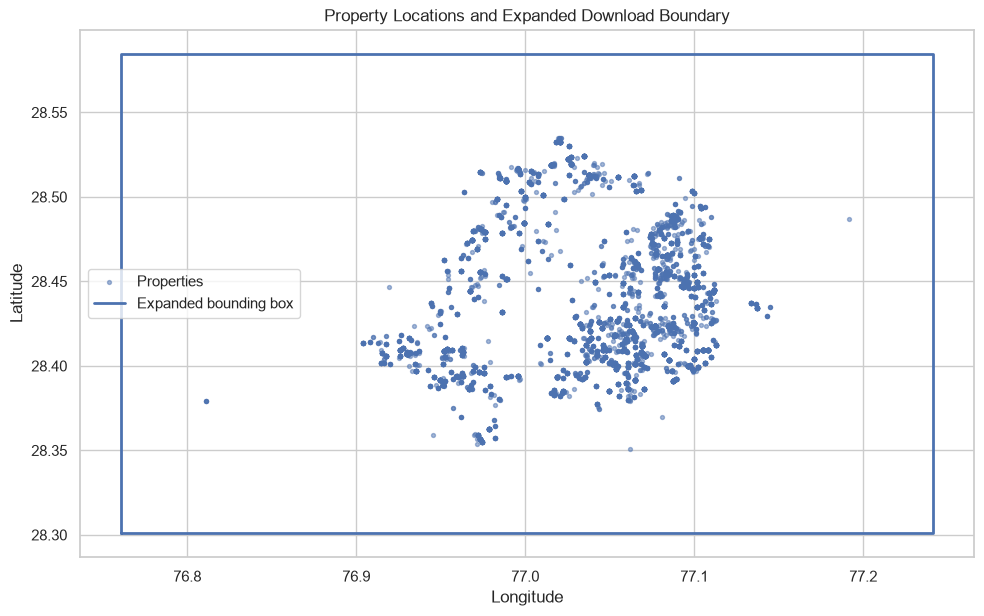

In [12]:
# Plot property locations and bounding box

fig, ax = plt.subplots(figsize=(10, 8))

ax.scatter(
    df["longitude"],
    df["latitude"],
    s=8,
    alpha=0.5,
    label="Properties"
)

# Draw the bounding box
ax.plot(
    [west, east, east, west, west],
    [south, south, north, north, south],
    linewidth=2,
    label="Expanded bounding box"
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Property Locations and Expanded Download Boundary")
ax.legend()
ax.set_aspect("equal", adjustable="box")

plt.tight_layout()
plt.show()

In [13]:
import json

bbox_info = {
    "west": west,
    "south": south,
    "east": east,
    "north": north,
    "buffer_degrees": BUF,
    "crs": "EPSG:4326"
}

bbox_path = "../data/external/gurgaon_bbox.json"

with open(bbox_path, "w", encoding="utf-8") as f:
    json.dump(bbox_info, f, indent=4)

print("Bounding box saved to:", bbox_path)

Bounding box saved to: ../data/external/gurgaon_bbox.json


In [14]:
print("OSMnx version:", ox.__version__)
print("Bounding box:", BBOX)
print("Property dataset shape:", df.shape)
print("GeoPackage folder exists:", os.path.isdir("../data/external"))

OSMnx version: 2.1.1
Bounding box: (np.float64(76.76076), np.float64(28.30093), np.float64(77.2415), np.float64(28.58481))
Property dataset shape: (7457, 20)
GeoPackage folder exists: True


In [16]:
# Part C: Download and cache OpenStreetMap features

def get_osm(name, tags, keep=("geometry",)):
    """
    Download OpenStreetMap features inside BBOX and save them
    locally as a GeoPackage.

    If a cached GeoPackage already exists, load it instead of
    downloading the data again.
    """

    path = f"../data/external/{name}.gpkg"

    # Reuse previously downloaded data
    if os.path.exists(path):
        print(f"Loading cached data: {name}")
        return gpd.read_file(path)

    print(f"Downloading from OpenStreetMap: {name}")
    print(f"Tags: {tags}")

    # Download features using the Part B bounding box
    gdf = ox.features_from_bbox(
        bbox=BBOX,
        tags=tags
    ).reset_index(drop=True)

    # Keep only the requested columns that actually exist
    cols = [col for col in keep if col in gdf.columns]
    gdf = gdf[cols].copy()

    # Save locally so future runs can reuse the result
    gdf.to_file(path, driver="GPKG")

    print(f"Saved {len(gdf)} features to {path}")

    return gdf

In [17]:
amen = {}

amen["railway"] = get_osm(
    "railway",
    {"railway": "station"},
    keep=("geometry", "name", "station")
)

print("Railway features downloaded:", len(amen["railway"]))

Tags: {'railway': 'station'}
Saved 67 features to ../data/external/railway.gpkg
Railway features downloaded: 67


In [18]:
amen["bus"] = get_osm(
    "bus",
    {"highway": "bus_stop"}
)

print("Bus stops downloaded:", len(amen["bus"]))

Tags: {'highway': 'bus_stop'}


ResponseStatusCodeError: 'overpass-api.de' responded: 502 Bad Gateway # 502 Gateway Timeout

This Overpass API server is currently at capacity. All query workers are busy
and the request queue is full.

## What to do

Retry your request using exponential backoff: wait a short interval, then retry.
If the request fails again, double the wait time and retry again.

## For heavy or automated use

This public endpoint is intended for browser-based and human-operated tools.
For automated or high-volume use, run a local Overpass API instance:

https://github.com/b1tw153/Overpass-API/blob/main/README.md


In [19]:
import os

for name in ["railway", "bus", "school", "hospital", "mall", "highway", "mainroad"]:
    path = f"../data/external/{name}.gpkg"

    if os.path.exists(path):
        print(f"{name:10s} SAVED ({os.path.getsize(path) / 1024:.1f} KB)")
    else:
        print(f"{name:10s} NOT SAVED")

railway    SAVED (104.0 KB)
bus        NOT SAVED
school     NOT SAVED
hospital   NOT SAVED
mall       NOT SAVED
highway    NOT SAVED
mainroad   NOT SAVED


In [20]:
import osmnx as ox

ox.settings.use_cache = True
ox.settings.requests_timeout = 180
ox.settings.overpass_url = "https://overpass.kumi.systems/api"

print("OSMnx version:", ox.__version__)
print("Overpass URL:", ox.settings.overpass_url)

OSMnx version: 2.1.1
Overpass URL: https://overpass.kumi.systems/api


In [21]:
import os
import time
import geopandas as gpd
import osmnx as ox

def get_osm(name, tags, keep=("geometry",), retries=3):
    path = f"../data/external/{name}.gpkg"

    # Reuse successfully saved data
    if os.path.exists(path):
        print(f"Loading cached data: {name}")
        return gpd.read_file(path)

    last_error = None

    for attempt in range(1, retries + 1):
        try:
            print(f"Downloading {name} (attempt {attempt}/{retries})")

            gdf = ox.features_from_bbox(
                bbox=BBOX,
                tags=tags
            ).reset_index(drop=True)

            cols = [col for col in keep if col in gdf.columns]
            gdf = gdf[cols].copy()

            # Save only after a successful download
            gdf.to_file(path, driver="GPKG")

            print(f"Saved {len(gdf)} features to {path}")
            return gdf

        except Exception as e:
            last_error = e
            print(f"Attempt {attempt} failed: {type(e).__name__}: {e}")

            if attempt < retries:
                time.sleep(10 * attempt)

    raise RuntimeError(
        f"Could not download '{name}' after {retries} attempts. "
        "Check the endpoint or try again later."
    ) from last_error

In [ ]:
amen["bus"] = get_osm(
    "bus",
    {"highway": "bus_stop"}
)

print("Bus stops downloaded:", len(amen["bus"]))

In [1]:
import os

path = "../data/external/bus.gpkg"

if os.path.exists(path):
    print("Bus cache exists:", os.path.getsize(path), "bytes")
else:
    print("No bus cache saved. The download did not finish successfully.")

No bus cache saved. The download did not finish successfully.


In [2]:
import requests
import osmnx as ox

url = ox.settings.overpass_url.rstrip("/") + "/status"

try:
    response = requests.get(url, timeout=20)
    print("Endpoint:", url)
    print("HTTP status:", response.status_code)
    print("Response:", response.text[:1000])
except requests.RequestException as e:
    print("Endpoint check failed:", repr(e))

Endpoint: https://overpass-api.de/api/status
HTTP status: 406
Response: <html>
<head><title>406 Not Acceptable</title></head>
<body>
<center><h1>406 Not Acceptable</h1></center>
<hr><center>nginx</center>
</body>
</html>



In [3]:
import osmnx as ox

ox.settings.overpass_url = "https://overpass.kumi.systems/api"
ox.settings.requests_timeout = 180
ox.settings.use_cache = True

print("Configured endpoint:", ox.settings.overpass_url)

Configured endpoint: https://overpass.kumi.systems/api


In [4]:
import requests

url = ox.settings.overpass_url.rstrip("/") + "/status"

try:
    response = requests.get(
        url,
        timeout=20,
        headers={"User-Agent": "RealEstateAccessibilityResearch/1.0"}
    )

    print("Endpoint:", url)
    print("HTTP status:", response.status_code)
    print("Response:", response.text[:1000])

except requests.RequestException as e:
    print("Request failed:", repr(e))

Request failed: ReadTimeout(ReadTimeoutError("HTTPSConnectionPool(host='overpass.kumi.systems', port=443): Read timed out. (read timeout=20)"))


In [5]:
import requests

url = "https://overpass.private.coffee/api/status"

try:
    response = requests.get(
        url,
        timeout=20,
        headers={"User-Agent": "RealEstateAccessibilityResearch/1.0"}
    )

    print("HTTP status:", response.status_code)
    print("Response:")
    print(response.text[:1000])

except requests.RequestException as e:
    print("Request failed:", repr(e))

Request failed: ReadTimeout(ReadTimeoutError("HTTPSConnectionPool(host='overpass.private.coffee', port=443): Read timed out. (read timeout=20)"))


In [6]:
import os

pbf_path = "../data/external/india-latest.osm.pbf"

if os.path.exists(pbf_path):
    size_gb = os.path.getsize(pbf_path) / (1024 ** 3)
    print(f"File found! Size: {size_gb:.2f} GB")
else:
    print("File not found. Check the file path.")

File found! Size: 0.21 GB


In [7]:
print("Gurgaon bounding box:", BBOX)

NameError: name 'BBOX' is not defined

In [8]:
import pandas as pd

df = pd.read_csv("../data/processed/clean_v2.csv")

BUF = 0.05

west = df["longitude"].min() - BUF
east = df["longitude"].max() + BUF
south = df["latitude"].min() - BUF
north = df["latitude"].max() + BUF

BBOX = (west, south, east, north)

print("Gurgaon bounding box:", BBOX)

Gurgaon bounding box: (np.float64(76.76076), np.float64(28.30093), np.float64(77.2415), np.float64(28.58481))


In [9]:
print("West:", west)
print("South:", south)
print("East:", east)
print("North:", north)

West: 76.76076
South: 28.30093
East: 77.2415
North: 28.58481


In [10]:
import os
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
from pyrosm import OSM

pbf_path = "../data/external/india-latest.osm.pbf"

assert os.path.exists(pbf_path), f"PBF file not found: {pbf_path}"

print("PBF file found.")
print(f"File size: {os.path.getsize(pbf_path) / (1024**3):.2f} GB")
print("Pyrosm imported successfully.")

PBF file found.
File size: 0.21 GB
Pyrosm imported successfully.


In [11]:
BBOX

(np.float64(76.76076),
 np.float64(28.30093),
 np.float64(77.2415),
 np.float64(28.58481))

In [12]:
osm = OSM(
    pbf_path,
    bounding_box=list(BBOX),
    keep_metadata=False
)

print("OSM reader initialized.")
print("Bounding box:", BBOX)

OSM reader initialized.
Bounding box: (np.float64(76.76076), np.float64(28.30093), np.float64(77.2415), np.float64(28.58481))


In [13]:
import os
import geopandas as gpd

railway_path = "../data/external/railway.gpkg"

if os.path.exists(railway_path):
    railway = gpd.read_file(railway_path)
    print(f"Railway file already exists: {len(railway)} features")
else:
    railway = osm.get_pois(
        custom_filter={"railway": ["station", "halt"]}
    )

    print(f"Railway features extracted: {len(railway)}")

    if not railway.empty:
        railway.to_file(railway_path, driver="GPKG")
        print("Railway data saved.")

Railway file already exists: 67 features


In [14]:
bus_path = "../data/external/bus.gpkg"

if os.path.exists(bus_path):
    bus = gpd.read_file(bus_path)
    print(f"Bus file already exists: {len(bus)} features")
else:
    bus = osm.get_pois(
        custom_filter={
            "highway": ["bus_stop"],
            "public_transport": ["platform"]
        }
    )

    print(f"Bus stops extracted: {len(bus)}")

    if not bus.empty:
        bus.to_file(bus_path, driver="GPKG")
        print("Bus stops saved to:", bus_path)

Reading india-latest.osm.pbf:  71%|#######   | 159M/224M [00:02<00:00, 75.2MB/s]

Bus stops extracted: 868
Bus stops saved to: ../data/external/bus.gpkg


In [15]:
railway = osm.get_pois(
    custom_filter={"railway": ["station", "halt"]}
)

print("Railway features:", len(railway))
print(railway.head())

Reading india-latest.osm.pbf:  66%|######5   | 147M/224M [00:02<00:01, 67.0MB/s]

Railway features: 70
          id        lon        lat  \
0  535297593  77.093002  28.481272   
1  554257763  77.120795  28.548779   
2  554257787  77.206707  28.544256   
3  910356438  77.186211  28.582204   
4  910356522  77.227689  28.578955   

                                                tags visible abandoned  \
0  {"name":"Sikanderpur","name:en":"Sikanderpur",...    True       NaN   
1  {"name":"Delhi Aerocity","name:fa":"\u0634\u06...    True       NaN   
2  {"internet_access":"no","name":"Hauz Khas (Yel...    True       NaN   
3  {"alt_name:ur":"\u062F\u0644\u06CC \u0635\u064...    True       NaN   
4  {"internet_access":"no","name":"Sewa Nagar","n...    True       NaN   

  construction disused  railway station subway                   geometry  \
0          NaN     NaN  station  subway    yes    POINT (77.093 28.48127)   
1          NaN     NaN  station  subway    yes  POINT (77.12079 28.54878)   
2          NaN     NaN  station  subway    yes  POINT (77.20671 28.54426) 

In [16]:
def save_gdf(gdf, name):
    output_path = f"../data/external/{name}.gpkg"

    if gdf is None or gdf.empty:
        print(f"No features found for {name}.")
        return

    gdf = gdf[gdf.geometry.notna()].copy()
    gdf.to_file(output_path, driver="GPKG")

    print(f"Saved {len(gdf)} features: {output_path}")

In [17]:
save_gdf(railway, "railway")

Saved 70 features: ../data/external/railway.gpkg


In [18]:
health_education = osm.get_pois(
    custom_filter={
        "amenity": ["school", "hospital"]
    }
)

print("Total school/hospital features:", len(health_education))
print(health_education.head())

Reading india-latest.osm.pbf:  77%|#######7  | 173M/224M [00:02<00:00, 81.1MB/s]

Total school/hospital features: 644
          id        lon        lat  \
0  249132373  77.087553  28.450969   
1  266378530  77.166546  28.508450   
2  266378545  77.163482  28.511716   
3  266535263  77.075931  28.462841   
4  271335768  77.138402  28.489639   

                                                tags  visible addr:city  \
0  {"addr:district":"Gurgaon","addr:state":"Harya...     True       NaN   
1                     {"created_by":"Potlatch 0.9a"}     True       NaN   
2                     {"created_by":"Potlatch 0.9a"}     True       NaN   
3  {"check_date":"2025-02-23","healthcare":"hospi...     True       NaN   
4                                                NaN     True       NaN   

                  addr:full addr:housenumber addr:postcode addr:place  ...  \
0  C-1, Sushant Lok Phase-1              NaN        122002        NaN  ...   
1                       NaN              NaN           NaN        NaN  ...   
2                       NaN              NaN      

In [19]:
schools = health_education[
    health_education["amenity"] == "school"
].copy()

hospitals = health_education[
    health_education["amenity"] == "hospital"
].copy()

print("Schools:", len(schools))
print("Hospitals:", len(hospitals))

Schools: 375
Hospitals: 269


In [20]:
save_gdf(schools, "school")
save_gdf(hospitals, "hospital")

Saved 375 features: ../data/external/school.gpkg
Saved 269 features: ../data/external/hospital.gpkg


In [24]:
import os
import geopandas as gpd

railway_path = "../data/external/railway.gpkg"

if os.path.exists(railway_path):
    railway = gpd.read_file(railway_path)
    print(f"Railway file already exists: {len(railway)} features")
else:
    railway = osm.get_pois(
        custom_filter={"railway": ["station", "halt"]}
    )

    print(f"Railway features extracted: {len(railway)}")

    if not railway.empty:
        railway.to_file(railway_path, driver="GPKG")
        print("Railway data saved.")

Railway file already exists: 70 features


In [25]:
bus_path = "../data/external/bus.gpkg"

if os.path.exists(bus_path):
    bus = gpd.read_file(bus_path)
    print(f"Bus file already exists: {len(bus)} features")
else:
    bus = osm.get_pois(
        custom_filter={
            "highway": ["bus_stop"],
            "public_transport": ["platform"]
        }
    )

    print(f"Bus stops extracted: {len(bus)}")

    if not bus.empty:
        bus.to_file(bus_path, driver="GPKG")
        print("Bus stops saved to:", bus_path)

Bus stops extracted: 868
Bus stops saved to: ../data/external/bus.gpkg


In [26]:
school_path = "../data/external/school.gpkg"

if os.path.exists(school_path):
    schools = gpd.read_file(school_path)
    print(f"School file already exists: {len(schools)} features")
else:
    schools = osm.get_pois(
        custom_filter={"amenity": ["school"]}
    )

    print("Schools extracted:", len(schools))

    if not schools.empty:
        schools.to_file(school_path, driver="GPKG")
        print("Schools saved:", school_path)

Reading india-latest.osm.pbf:  66%|######5   | 147M/224M [00:02<00:01, 68.0MB/s]

Schools extracted: 375
Schools saved: ../data/external/school.gpkg


In [27]:
hospital_path = "../data/external/hospital.gpkg"

if os.path.exists(hospital_path):
    hospitals = gpd.read_file(hospital_path)
    print(f"Hospital file already exists: {len(hospitals)} features")
else:
    hospitals = osm.get_pois(
        custom_filter={"amenity": ["hospital"]}
    )

    print("Hospitals extracted:", len(hospitals))

    if not hospitals.empty:
        hospitals.to_file(hospital_path, driver="GPKG")
        print("Hospitals saved:", hospital_path)

Reading india-latest.osm.pbf:  67%|######6   | 149M/224M [00:02<00:01, 70.0MB/s]

Hospitals extracted: 269
Hospitals saved: ../data/external/hospital.gpkg


In [28]:
mall_path = "../data/external/mall.gpkg"

if os.path.exists(mall_path):
    malls = gpd.read_file(mall_path)
    print(f"Mall file already exists: {len(malls)} features")
else:
    malls = osm.get_pois(
        custom_filter={
            "shop": ["mall"],
            "amenity": ["marketplace"]
        }
    )

    print("Malls and marketplaces extracted:", len(malls))

    if not malls.empty:
        malls.to_file(mall_path, driver="GPKG")
        print("Mall data saved:", mall_path)

Reading india-latest.osm.pbf:  59%|#####9    | 133M/224M [00:02<00:01, 63.4MB/s]

Malls and marketplaces extracted: 104
Mall data saved: ../data/external/mall.gpkg


In [29]:
amenity_files = [
    "railway",
    "bus",
    "school",
    "hospital",
    "mall"
]

for name in amenity_files:
    path = f"../data/external/{name}.gpkg"

    if os.path.exists(path):
        gdf = gpd.read_file(path)
        print(f"{name:10} | {len(gdf):5} features")
    else:
        print(f"{name:10} | NOT SAVED")

railway    |    70 features
bus        |   868 features
school     |   375 features
hospital   |   269 features
mall       |   104 features


In [30]:
highway_path = "../data/external/highway.gpkg"

if os.path.exists(highway_path):
    highways = gpd.read_file(highway_path)
    print(f"Highway file already exists: {len(highways)} features")
else:
    highways = osm.get_network(
        network_type="driving",
        custom_filter={"highway": ["motorway", "trunk"]}
    )

    print("Highway segments extracted:", len(highways))

    if not highways.empty:
        highways.to_file(highway_path, driver="GPKG")
        print("Highways saved:", highway_path)

Reading india-latest.osm.pbf:  73%|#######2  | 163M/224M [00:02<00:00, 73.6MB/s]

Highway segments extracted: 79848
Highways saved: ../data/external/highway.gpkg


In [31]:
mainroad_path = "../data/external/mainroad.gpkg"

if os.path.exists(mainroad_path):
    mainroads = gpd.read_file(mainroad_path)
    print(f"Main road file already exists: {len(mainroads)} features")
else:
    mainroads = osm.get_network(
        network_type="driving",
        custom_filter={"highway": ["primary"]}
    )

    print("Main road segments extracted:", len(mainroads))

    if not mainroads.empty:
        mainroads.to_file(mainroad_path, driver="GPKG")
        print("Main roads saved:", mainroad_path)

Reading india-latest.osm.pbf:  57%|#####6    | 128M/224M [00:02<00:01, 62.9MB/s]

Main road segments extracted: 80161
Main roads saved: ../data/external/mainroad.gpkg


In [32]:
amenity_files = [
    "railway",
    "bus",
    "school",
    "hospital",
    "mall",
    "highway",
    "mainroad"
]

for name in amenity_files:
    path = f"../data/external/{name}.gpkg"

    if os.path.exists(path):
        gdf = gpd.read_file(path)
        print(
            f"{name:10} | "
            f"{len(gdf):6} features | "
            f"{gdf.geometry.notna().sum():6} valid geometries"
        )
    else:
        print(f"{name:10} | NOT SAVED")

railway    |     70 features |     70 valid geometries
bus        |    868 features |    868 valid geometries
school     |    375 features |    375 valid geometries
hospital   |    269 features |    269 valid geometries
mall       |    104 features |    104 valid geometries
highway    |  79848 features |  79848 valid geometries
mainroad   |  80161 features |  80161 valid geometries


In [33]:
import os
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

In [34]:
df = pd.read_csv("../data/processed/clean_v2.csv")

print("Properties:", len(df))
print("Columns:", df.columns.tolist())

print("\nLatitude range:")
print(df["latitude"].min(), "to", df["latitude"].max())

print("\nLongitude range:")
print(df["longitude"].min(), "to", df["longitude"].max())

Properties: 7457
Columns: ['prop_id', 'latitude', 'longitude', 'property_type', 'owntype', 'bedroom_num', 'bathroom_num', 'balcony_num', 'furnish', 'facing', 'age', 'floor_num', 'total_floor', 'total_landmark_count', 'area_sqft', 'area_is_carpet', 'locality_grouped', 'price_lakhs']

Latitude range:
28.35093 to 28.53481

Longitude range:
76.81076 to 77.1915


In [35]:
amenity_names = [
    "railway",
    "bus",
    "school",
    "hospital",
    "mall",
    "highway",
    "mainroad"
]

amen = {}

for name in amenity_names:
    path = f"../data/external/{name}.gpkg"

    if os.path.exists(path):
        amen[name] = gpd.read_file(path)
        print(f"{name:10}: {len(amen[name]):6} features")
    else:
        print(f"{name:10}: FILE NOT FOUND")

railway   :     70 features
bus       :    868 features
school    :    375 features
hospital  :    269 features
mall      :    104 features
highway   :  79848 features
mainroad  :  80161 features


In [36]:
for name, gdf in amen.items():
    print(f"{name:10}: CRS = {gdf.crs}")

railway   : CRS = EPSG:4326
bus       : CRS = EPSG:4326
school    : CRS = EPSG:4326
hospital  : CRS = EPSG:4326
mall      : CRS = EPSG:4326
highway   : CRS = EPSG:4326
mainroad  : CRS = EPSG:4326


In [37]:
for name, gdf in amen.items():
    print(f"\n{name.upper()}")
    print("Empty dataset:", gdf.empty)
    print("Missing geometries:", gdf.geometry.isna().sum())
    print("Geometry types:", gdf.geom_type.value_counts().to_dict())


RAILWAY
Empty dataset: False
Missing geometries: 0
Geometry types: {'Point': 69, 'Polygon': 1}

BUS
Empty dataset: False
Missing geometries: 0
Geometry types: {'Point': 829, 'LineString': 23, 'Polygon': 16}

SCHOOL
Empty dataset: False
Missing geometries: 0
Geometry types: {'Polygon': 181, 'Point': 108, 'LineString': 84, 'MultiPolygon': 2}

HOSPITAL
Empty dataset: False
Missing geometries: 0
Geometry types: {'Point': 209, 'Polygon': 47, 'LineString': 12, 'MultiPolygon': 1}

MALL
Empty dataset: False
Missing geometries: 0
Geometry types: {'Polygon': 65, 'Point': 34, 'LineString': 3, 'MultiPolygon': 2}

HIGHWAY
Empty dataset: False
Missing geometries: 0
Geometry types: {'LineString': 79848}

MAINROAD
Empty dataset: False
Missing geometries: 0
Geometry types: {'LineString': 80161}


In [38]:
for name in amen:
    if not amen[name].empty:
        if amen[name].crs is None:
            raise ValueError(
                f"{name} has no CRS. Check its coordinate reference system first."
            )

        amen[name] = amen[name].to_crs("EPSG:4326")

print("Amenity layers converted to EPSG:4326.")

Amenity layers converted to EPSG:4326.


In [39]:
for name, gdf in amen.items():
    if gdf.empty:
        print(f"{name:10}: EMPTY")
        continue

    bounds = gdf.total_bounds

    print(
        f"{name:10}: "
        f"Longitude {bounds[0]:.5f} to {bounds[2]:.5f}, "
        f"Latitude {bounds[1]:.5f} to {bounds[3]:.5f}"
    )

railway   : Longitude 76.79942 to 77.23932, Latitude 28.37281 to 28.58304
bus       : Longitude 76.88261 to 77.24144, Latitude 28.33348 to 28.58480
school    : Longitude 76.76930 to 77.24283, Latitude 28.30226 to 28.58669
hospital  : Longitude 76.77013 to 77.24124, Latitude 28.32007 to 28.58529
mall      : Longitude 76.96320 to 77.24127, Latitude 28.36067 to 28.58479
highway   : Longitude 76.66822 to 77.28035, Latitude 28.21687 to 28.63915
mainroad  : Longitude 76.66822 to 77.28035, Latitude 28.21687 to 28.63915


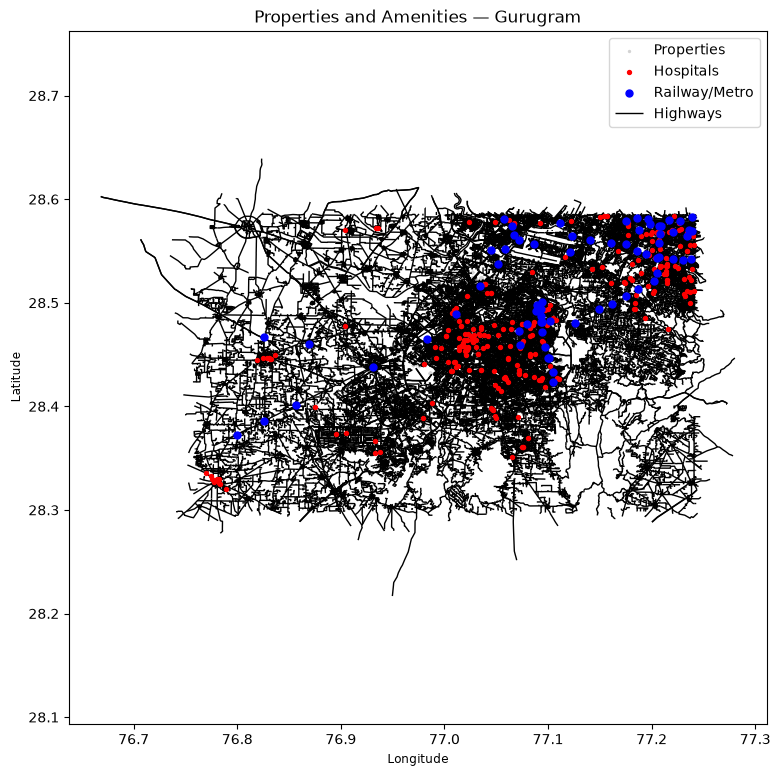

Figure saved to reports/figures/06_amenity_overlay.png


In [40]:
fig, ax = plt.subplots(figsize=(9, 9))

# Plot properties
ax.scatter(
    df["longitude"],
    df["latitude"],
    s=2,
    c="lightgrey",
    label="Properties",
    zorder=1
)

# Plot hospitals
if not amen["hospital"].empty:
    hospitals_utm = amen["hospital"].to_crs("EPSG:32643")
    hospital_points = hospitals_utm.geometry.centroid.to_crs("EPSG:4326")

    hospital_points.plot(
        ax=ax,
        markersize=8,
        color="red",
        label="Hospitals",
        zorder=3
    )

# Plot railway stations
if not amen["railway"].empty:
    railway_utm = amen["railway"].to_crs("EPSG:32643")
    railway_points = railway_utm.geometry.centroid.to_crs("EPSG:4326")

    railway_points.plot(
        ax=ax,
        markersize=25,
        color="blue",
        label="Railway/Metro",
        zorder=4
    )

# Plot highways
if not amen["highway"].empty:
    highways = amen["highway"].to_crs("EPSG:4326")

    highways.plot(
        ax=ax,
        color="black",
        linewidth=1,
        label="Highways",
        zorder=2
    )

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Properties and Amenities — Gurugram")
ax.legend()
ax.set_aspect("equal", adjustable="datalim")

plt.savefig(
    "../reports/figures/06_amenity_overlay.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to reports/figures/06_amenity_overlay.png")

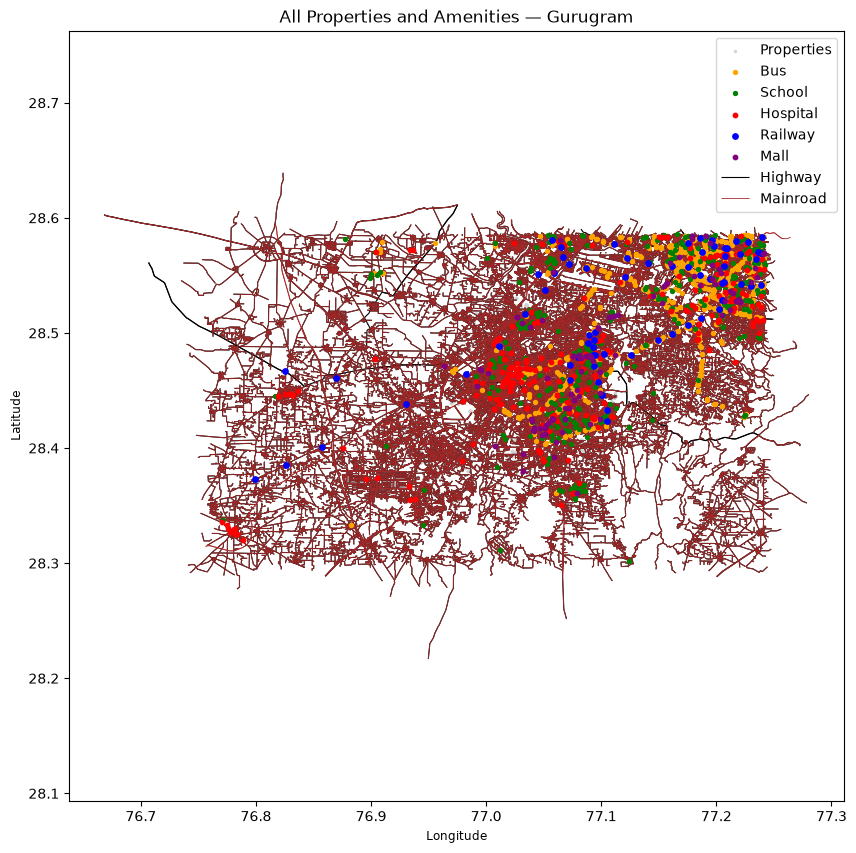

Saved: reports/figures/06_all_amenities_overlay.png


In [41]:
fig, ax = plt.subplots(figsize=(10, 10))

ax.scatter(
    df["longitude"],
    df["latitude"],
    s=2,
    color="lightgrey",
    label="Properties",
    zorder=1
)

plot_settings = {
    "bus": {"color": "orange", "markersize": 8},
    "school": {"color": "green", "markersize": 8},
    "hospital": {"color": "red", "markersize": 10},
    "railway": {"color": "blue", "markersize": 15},
    "mall": {"color": "purple", "markersize": 10},
    "highway": {"color": "black", "linewidth": 0.8},
    "mainroad": {"color": "brown", "linewidth": 0.6}
}

for name, settings in plot_settings.items():
    gdf = amen[name]

    if gdf.empty:
        print(f"Skipping empty layer: {name}")
        continue

    gdf = gdf.to_crs("EPSG:4326")

    if name in ["highway", "mainroad"]:
        gdf.plot(
            ax=ax,
            color=settings["color"],
            linewidth=settings["linewidth"],
            label=name.title(),
            zorder=2
        )
    else:
        projected = gdf.to_crs("EPSG:32643")
        points = projected.geometry.centroid.to_crs("EPSG:4326")

        points.plot(
            ax=ax,
            color=settings["color"],
            markersize=settings["markersize"],
            label=name.title(),
            zorder=3
        )

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("All Properties and Amenities — Gurugram")
ax.legend(loc="best")
ax.set_aspect("equal", adjustable="datalim")

plt.savefig(
    "../reports/figures/06_all_amenities_overlay.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Saved: reports/figures/06_all_amenities_overlay.png")

In [42]:
figure_path = "../reports/figures/06_amenity_overlay.png"
figure_path_all = "../reports/figures/06_all_amenities_overlay.png"

print("Main overlay exists:", os.path.exists(figure_path))
print("All-amenities overlay exists:", os.path.exists(figure_path_all))

Main overlay exists: True
All-amenities overlay exists: True


In [43]:
UTM = "EPSG:32643"

In [44]:
df = pd.read_csv("../data/processed/clean_v2.csv")

print("Properties:", len(df))
print("Unique property IDs:", df["prop_id"].nunique())
print(df[["prop_id", "longitude", "latitude"]].head())

Properties: 7457
Unique property IDs: 7457
     prop_id  longitude   latitude
0  O71585872  76.962792  28.406534
1  T71585466  76.951328  28.388907
2  I71493958  77.015115  28.518677
3  X71361930  76.986110  28.478440
4  N71483500  77.012620  28.416400


In [45]:
assert "prop_id" in df.columns
assert df["prop_id"].is_unique, "prop_id contains duplicates."
assert df[["longitude", "latitude"]].notna().all().all()

print("Property data validated.")

Property data validated.


In [46]:
props = gpd.GeoDataFrame(
    df[["prop_id"]].copy(),
    geometry=gpd.points_from_xy(
        df["longitude"],
        df["latitude"]
    ),
    crs="EPSG:4326"
).to_crs(UTM)

print("Property GeoDataFrame created.")
print("CRS:", props.crs)
print("Number of properties:", len(props))

Property GeoDataFrame created.
CRS: EPSG:32643
Number of properties: 7457


In [47]:
def nearest_km(props, amenity_gdf, colname):
    if amenity_gdf is None or amenity_gdf.empty:
        return pd.Series(
            np.nan,
            index=props.index,
            name=colname
        )

    if amenity_gdf.crs is None:
        raise ValueError(
            f"{colname}: amenity dataset has no CRS."
        )

    # Convert amenities to the same projected CRS.
    a = amenity_gdf.to_crs(UTM)[["geometry"]].copy()

    # Remove missing geometries.
    a = a[a.geometry.notna() & ~a.geometry.is_empty]

    if a.empty:
        return pd.Series(
            np.nan,
            index=props.index,
            name=colname
        )

    # Find the nearest amenity for every property.
    joined = gpd.sjoin_nearest(
        props[["geometry"]],
        a,
        how="left",
        distance_col="_distance_m"
    )

    # Resolve duplicate rows caused by equidistant nearest features.
    joined = joined[
        ~joined.index.duplicated(keep="first")
    ]

    # Convert metres to kilometres and restore property order.
    distances = (
        joined["_distance_m"]
        .reindex(props.index)
        / 1000
    )

    distances.name = colname

    return distances

In [48]:
feats = df[["prop_id"]].copy()

for name in amenity_names:
    if name in amen and amen[name] is not None and not amen[name].empty:
        colname = f"dist_{name}_km"

        feats[colname] = nearest_km(
            props,
            amen[name],
            colname
        ).to_numpy()

        print(f"Calculated: {colname}")

    else:
        print(f"Skipped {name}: dataset missing or empty")

Calculated: dist_railway_km
Calculated: dist_bus_km
Calculated: dist_school_km
Calculated: dist_hospital_km
Calculated: dist_mall_km
Calculated: dist_highway_km
Calculated: dist_mainroad_km


In [49]:
print("Feature dataset shape:", feats.shape)

display(feats.head())

display(feats.describe().T.round(3))

Feature dataset shape: (7457, 8)


,prop_id,dist_railway_km,dist_bus_km,dist_school_km,dist_hospital_km,dist_mall_km,dist_highway_km,dist_mainroad_km
0,O71585872,4.718649,5.866253,4.760367,2.511597,4.430818,0.006102,0.006102
1,T71585466,5.834544,7.903888,2.774529,2.715225,5.692716,0.005423,0.005423
2,I71493958,1.861994,1.937073,1.686636,1.559152,1.261223,0.004921,0.004921
3,X71361930,1.569207,1.464931,1.510960,1.772932,1.371881,0.022995,0.022995
4,N71483500,6.086466,1.605551,0.582855,1.998448,1.723163,0.044808,0.044808


,count,mean,std,min,25%,50%,75%,max
dist_railway_km,7457.0,3.239,2.367,0.010,1.175,2.841,4.851,10.286
dist_bus_km,7457.0,1.926,2.306,0.021,0.501,0.899,2.171,8.748
dist_school_km,7457.0,1.150,1.162,0.000,0.292,0.654,1.664,5.745
dist_hospital_km,7457.0,1.408,1.064,0.005,0.596,1.048,1.998,6.134
dist_mall_km,7457.0,1.795,1.934,0.002,0.603,1.034,2.174,18.095
dist_highway_km,7457.0,0.022,0.029,0.000,0.006,0.014,0.025,0.239
dist_mainroad_km,7457.0,0.022,0.029,0.000,0.006,0.014,0.025,0.239


In [50]:
print("Missing distances:")
display(feats.isna().sum().to_frame("missing_count"))

Missing distances:


,missing_count
prop_id,0
dist_railway_km,0
dist_bus_km,0
dist_school_km,0
dist_hospital_km,0
dist_mall_km,0
dist_highway_km,0
dist_mainroad_km,0


In [51]:
distance_cols = [
    col for col in feats.columns
    if col.startswith("dist_")
]

for col in distance_cols:
    print(f"\n{col}")
    print(feats[col].describe().round(3))


dist_railway_km
count    7457.000
mean        3.239
std         2.367
min         0.010
25%         1.175
50%         2.841
75%         4.851
max        10.286
Name: dist_railway_km, dtype: float64

dist_bus_km
count    7457.000
mean        1.926
std         2.306
min         0.021
25%         0.501
50%         0.899
75%         2.171
max         8.748
Name: dist_bus_km, dtype: float64

dist_school_km
count    7457.000
mean        1.150
std         1.162
min         0.000
25%         0.292
50%         0.654
75%         1.664
max         5.745
Name: dist_school_km, dtype: float64

dist_hospital_km
count    7457.000
mean        1.408
std         1.064
min         0.005
25%         0.596
50%         1.048
75%         1.998
max         6.134
Name: dist_hospital_km, dtype: float64

dist_mall_km
count    7457.000
mean        1.795
std         1.934
min         0.002
25%         0.603
50%         1.034
75%         2.174
max        18.095
Name: dist_mall_km, dtype: float64

dist_highway_km
co

In [52]:
output_path = "../data/processed/distance_features.csv"

feats.to_csv(output_path, index=False)

print("Distance features saved to:", output_path)
print("Rows:", len(feats))
print("Columns:", len(feats.columns))

Distance features saved to: ../data/processed/distance_features.csv
Rows: 7457
Columns: 8


In [53]:
check = pd.read_csv(
    "../data/processed/distance_features.csv"
)

assert len(check) == len(df)
assert check["prop_id"].equals(df["prop_id"])

print("Saved file verified successfully.")
print(check.head())

Saved file verified successfully.
     prop_id  dist_railway_km  dist_bus_km  dist_school_km  dist_hospital_km  \
0  O71585872         4.718649     5.866253        4.760367          2.511597   
1  T71585466         5.834544     7.903888        2.774529          2.715225   
2  I71493958         1.861994     1.937073        1.686636          1.559152   
3  X71361930         1.569207     1.464931        1.510960          1.772932   
4  N71483500         6.086466     1.605551        0.582855          1.998448   

   dist_mall_km  dist_highway_km  dist_mainroad_km  
0      4.430818         0.006102          0.006102  
1      5.692716         0.005423          0.005423  
2      1.261223         0.004921          0.004921  
3      1.371881         0.022995          0.022995  
4      1.723163         0.044808          0.044808  


In [54]:
import numpy as np
import pandas as pd
import geopandas as gpd
from scipy.spatial import cKDTree
import os

In [56]:
print("Properties:", len(props))
print("Property CRS:", props.crs)

for name in ["school", "hospital", "bus", "mall"]:
    if name in amen:
        print(f"{name:10}: {len(amen[name])} features")
    else:
        print(f"{name:10}: NOT LOADED")

Properties: 7457
Property CRS: EPSG:32643
school    : 375 features
hospital  : 269 features
bus       : 868 features
mall      : 104 features


In [57]:
print("Properties:", len(props))
print("Property CRS:", props.crs)

for name in ["school", "hospital", "bus", "mall"]:
    if name in amen:
        print(f"{name:10}: {len(amen[name])} features")
    else:
        print(f"{name:10}: NOT LOADED")

Properties: 7457
Property CRS: EPSG:32643
school    : 375 features
hospital  : 269 features
bus       : 868 features
mall      : 104 features


In [58]:
def count_within(props, amenity_gdf, radius_m, UTM="EPSG:32643"):
    """
    Count amenities within radius_m metres of each property.

    Returns one count for each property, preserving property order.
    """

    if amenity_gdf is None or amenity_gdf.empty:
        return np.zeros(len(props), dtype=int)

    if props.crs is None or amenity_gdf.crs is None:
        raise ValueError("Both properties and amenities must have a CRS.")

    # Project both datasets into metres.
    amenity_projected = amenity_gdf.to_crs(UTM)
    properties_projected = props.to_crs(UTM)

    # Remove missing or empty geometries.
    amenity_projected = amenity_projected[
        amenity_projected.geometry.notna()
        & ~amenity_projected.geometry.is_empty
    ]

    if amenity_projected.empty:
        return np.zeros(len(props), dtype=int)

    # Convert polygon and line geometries to representative points.
    # Point geometries remain unchanged.
    amenity_points = amenity_projected.geometry.copy()

    non_points = ~amenity_points.geom_type.isin(["Point", "MultiPoint"])
    amenity_points.loc[non_points] = amenity_points.loc[non_points].centroid

    # Build the spatial index.
    tree = cKDTree(
        np.column_stack([
            amenity_points.x,
            amenity_points.y
        ])
    )

    # Property coordinates.
    query_points = np.column_stack([
        properties_projected.geometry.x,
        properties_projected.geometry.y
    ])

    # Find and count amenities within the specified radius.
    matches = tree.query_ball_point(query_points, r=radius_m)

    return np.array([len(items) for items in matches], dtype=int)

In [59]:
def count_within(props, amenity_gdf, radius_m, UTM="EPSG:32643"):
    """
    Count amenities within radius_m metres of each property.

    Returns one count for each property, preserving property order.
    """

    if amenity_gdf is None or amenity_gdf.empty:
        return np.zeros(len(props), dtype=int)

    if props.crs is None or amenity_gdf.crs is None:
        raise ValueError("Both properties and amenities must have a CRS.")

    # Project both datasets into metres.
    amenity_projected = amenity_gdf.to_crs(UTM)
    properties_projected = props.to_crs(UTM)

    # Remove missing or empty geometries.
    amenity_projected = amenity_projected[
        amenity_projected.geometry.notna()
        & ~amenity_projected.geometry.is_empty
    ]

    if amenity_projected.empty:
        return np.zeros(len(props), dtype=int)

    # Convert polygon and line geometries to representative points.
    # Point geometries remain unchanged.
    amenity_points = amenity_projected.geometry.copy()

    non_points = ~amenity_points.geom_type.isin(["Point", "MultiPoint"])
    amenity_points.loc[non_points] = amenity_points.loc[non_points].centroid

    # Build the spatial index.
    tree = cKDTree(
        np.column_stack([
            amenity_points.x,
            amenity_points.y
        ])
    )

    # Property coordinates.
    query_points = np.column_stack([
        properties_projected.geometry.x,
        properties_projected.geometry.y
    ])

    # Find and count amenities within the specified radius.
    matches = tree.query_ball_point(query_points, r=radius_m)

    return np.array([len(items) for items in matches], dtype=int)

In [60]:
count_amenities = ["school", "hospital", "bus", "mall"]
radii = [1000, 2000]

for name in count_amenities:
    for radius in radii:
        colname = f"n_{name}_{radius // 1000}km"

        feats[colname] = count_within(
            props,
            amen[name],
            radius
        )

        print(f"Calculated {colname}")

print("Density features calculated successfully.")

Calculated n_school_1km
Calculated n_school_2km
Calculated n_hospital_1km
Calculated n_hospital_2km
Calculated n_bus_1km
Calculated n_bus_2km
Calculated n_mall_1km
Calculated n_mall_2km
Density features calculated successfully.


In [61]:
density_cols = [
    col for col in feats.columns
    if col.startswith("n_")
]

print("Number of density features:", len(density_cols))
print("Density feature columns:", density_cols)

display(feats[density_cols].head())

Number of density features: 8
Density feature columns: ['n_school_1km', 'n_school_2km', 'n_hospital_1km', 'n_hospital_2km', 'n_bus_1km', 'n_bus_2km', 'n_mall_1km', 'n_mall_2km']


,n_school_1km,n_school_2km,n_hospital_1km,n_hospital_2km,n_bus_1km,n_bus_2km,n_mall_1km,n_mall_2km
0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0
2,0,4,0,1,0,1,0,3
3,0,3,0,3,0,4,0,2
4,3,3,0,0,0,8,0,1


In [62]:
density_cols = [
    col for col in feats.columns
    if col.startswith("n_")
]

print("Number of density features:", len(density_cols))
print("Density feature columns:", density_cols)

display(feats[density_cols].head())

Number of density features: 8
Density feature columns: ['n_school_1km', 'n_school_2km', 'n_hospital_1km', 'n_hospital_2km', 'n_bus_1km', 'n_bus_2km', 'n_mall_1km', 'n_mall_2km']


,n_school_1km,n_school_2km,n_hospital_1km,n_hospital_2km,n_bus_1km,n_bus_2km,n_mall_1km,n_mall_2km
0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0
2,0,4,0,1,0,1,0,3
3,0,3,0,3,0,4,0,2
4,3,3,0,0,0,8,0,1


In [63]:
display(feats[density_cols].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
n_school_1km,7457.0,2.52,3.32,0.0,0.0,1.0,4.0,16.0
n_school_2km,7457.0,9.14,8.85,0.0,1.0,7.0,15.0,36.0
n_hospital_1km,7457.0,1.37,1.99,0.0,0.0,0.0,2.0,25.0
n_hospital_2km,7457.0,5.48,5.29,0.0,0.0,5.0,9.0,45.0
n_bus_1km,7457.0,2.60,3.51,0.0,0.0,1.0,4.0,19.0
n_bus_2km,7457.0,10.26,10.16,0.0,0.0,8.0,18.0,40.0
n_mall_1km,7457.0,1.40,2.53,0.0,0.0,0.0,1.0,13.0
n_mall_2km,7457.0,5.03,5.85,0.0,0.0,2.0,8.0,22.0


In [65]:
for name in count_amenities:
    col_1km = f"n_{name}_1km"
    col_2km = f"n_{name}_2km"

    assert (feats[col_2km] >= feats[col_1km]).all(), (
        f"Count validation failed for {name}"
    )

print("Radius consistency checks passed.")

Radius consistency checks passed.


In [67]:
output_path = "../data/processed/location_features.csv"

feats.to_csv(output_path, index=False)

print("Location features saved to:", output_path)
print("Rows:", len(feats))
print("Columns:", len(feats.columns))

Location features saved to: ../data/processed/location_features.csv
Rows: 7457
Columns: 16


In [68]:
saved = pd.read_csv("../data/processed/location_features.csv")

print("Saved dataset shape:", saved.shape)
print("\nColumns:")
print(saved.columns.tolist())

assert len(saved) == len(df)
assert saved["prop_id"].equals(df["prop_id"])

print("\nPart F completed successfully.")

Saved dataset shape: (7457, 16)

Columns:
['prop_id', 'dist_railway_km', 'dist_bus_km', 'dist_school_km', 'dist_hospital_km', 'dist_mall_km', 'dist_highway_km', 'dist_mainroad_km', 'n_school_1km', 'n_school_2km', 'n_hospital_1km', 'n_hospital_2km', 'n_bus_1km', 'n_bus_2km', 'n_mall_1km', 'n_mall_2km']

Part F completed successfully.


In [69]:
print("Missing values in features:")
missing = feats.isna().sum()
print(missing[missing > 0])

Missing values in features:
Series([], dtype: int64)


In [70]:
dist_cols = [
    col for col in feats.columns
    if col.startswith("dist_")
]

zero_counts = (feats[dist_cols] == 0).sum()

print("Exact zero distances:")
print(zero_counts)

Exact zero distances:
dist_railway_km       0
dist_bus_km           0
dist_school_km      137
dist_hospital_km      0
dist_mall_km          0
dist_highway_km       0
dist_mainroad_km      0
dtype: int64


In [71]:
if "dist_hospital_km" in feats.columns:
    zero_hospital_ids = feats.loc[
        feats["dist_hospital_km"] == 0,
        "prop_id"
    ]

    print("Properties with zero hospital distance:", len(zero_hospital_ids))
    print(zero_hospital_ids.head(10).tolist())

Properties with zero hospital distance: 0
[]


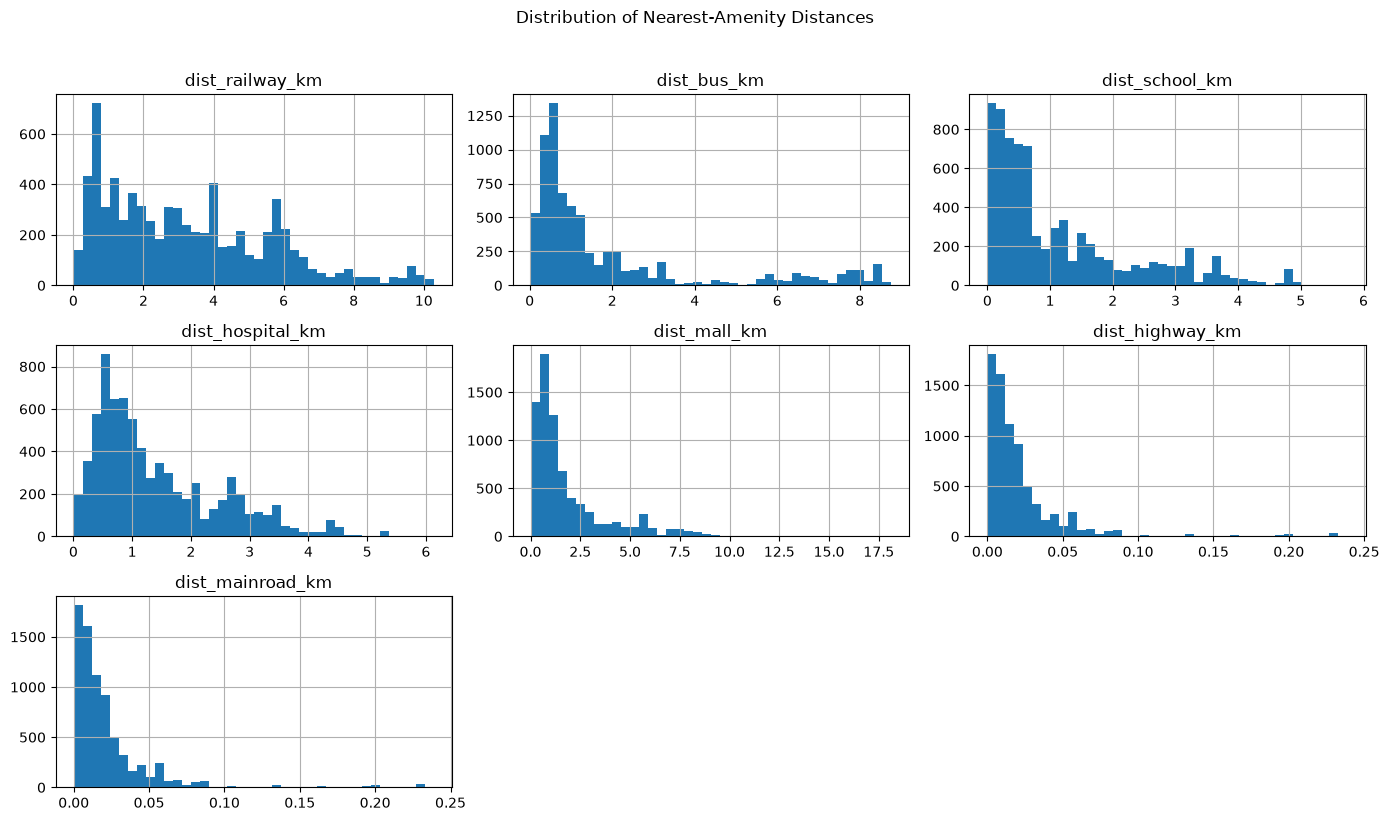

In [72]:
dist_cols = [
    col for col in feats.columns
    if col.startswith("dist_")
]

feats[dist_cols].hist(
    bins=40,
    figsize=(14, 8)
)

plt.suptitle("Distribution of Nearest-Amenity Distances", y=1.02)
plt.tight_layout()
plt.show()

In [73]:
print("Maximum distance for each amenity (km):")

display(
    feats[dist_cols]
    .max()
    .sort_values(ascending=False)
    .to_frame("max_distance_km")
)

Maximum distance for each amenity (km):


,max_distance_km
dist_mall_km,18.095132
dist_railway_km,10.286262
dist_bus_km,8.747685
dist_hospital_km,6.134312
dist_school_km,5.744643
dist_highway_km,0.238928
dist_mainroad_km,0.238928


In [74]:
far_counts = (feats[dist_cols] > 20).sum()

print("Distances greater than 20 km:")
display(far_counts.to_frame("count"))

Distances greater than 20 km:


,count
dist_railway_km,0
dist_bus_km,0
dist_school_km,0
dist_hospital_km,0
dist_mall_km,0
dist_highway_km,0
dist_mainroad_km,0


In [75]:
density_cols = [
    col for col in feats.columns
    if col.startswith("n_")
]

print("Density feature columns:")
print(density_cols)

if density_cols:
    print("\nMissing density values:")
    print(feats[density_cols].isna().sum())

    print("\nDensity summary:")
    display(feats[density_cols].describe().T.round(2))

Density feature columns:
['n_school_1km', 'n_school_2km', 'n_hospital_1km', 'n_hospital_2km', 'n_bus_1km', 'n_bus_2km', 'n_mall_1km', 'n_mall_2km']

Missing density values:
n_school_1km      0
n_school_2km      0
n_hospital_1km    0
n_hospital_2km    0
n_bus_1km         0
n_bus_2km         0
n_mall_1km        0
n_mall_2km        0
dtype: int64

Density summary:


,count,mean,std,min,25%,50%,75%,max
n_school_1km,7457.0,2.52,3.32,0.0,0.0,1.0,4.0,16.0
n_school_2km,7457.0,9.14,8.85,0.0,1.0,7.0,15.0,36.0
n_hospital_1km,7457.0,1.37,1.99,0.0,0.0,0.0,2.0,25.0
n_hospital_2km,7457.0,5.48,5.29,0.0,0.0,5.0,9.0,45.0
n_bus_1km,7457.0,2.60,3.51,0.0,0.0,1.0,4.0,19.0
n_bus_2km,7457.0,10.26,10.16,0.0,0.0,8.0,18.0,40.0
n_mall_1km,7457.0,1.40,2.53,0.0,0.0,0.0,1.0,13.0
n_mall_2km,7457.0,5.03,5.85,0.0,0.0,2.0,8.0,22.0


In [76]:
for name in ["school", "hospital", "bus", "mall"]:
    col_1km = f"n_{name}_1km"
    col_2km = f"n_{name}_2km"

    if col_1km in feats.columns and col_2km in feats.columns:
        assert (
            feats[col_2km] >= feats[col_1km]
        ).all(), f"Invalid counts for {name}"

print("Density count checks passed.")

Density count checks passed.


In [77]:
check_df = df[
    ["prop_id", "latitude", "longitude", "price_lakhs"]
].copy()

check_df = check_df.merge(
    feats,
    on="prop_id",
    how="left",
    validate="one_to_one"
)

# Select three properties spread across the dataset.
sample_properties = check_df.iloc[
    np.linspace(0, len(check_df) - 1, 3, dtype=int)
].copy()

cols_to_show = [
    "prop_id",
    "latitude",
    "longitude",
    "dist_railway_km",
    "dist_hospital_km",
    "dist_school_km"
]

cols_to_show = [
    col for col in cols_to_show
    if col in sample_properties.columns
]

display(sample_properties[cols_to_show])

,prop_id,latitude,longitude,dist_railway_km,dist_hospital_km,dist_school_km
0,O71585872,28.406534,76.962792,4.718649,2.511597,4.760367
3728,P70226898,28.388726,76.967902,6.592212,1.090684,3.394469
7456,C71777090,28.399078,77.102017,2.708238,2.145694,1.644122


In [78]:
suspicious = []

for col in dist_cols:
    for idx, value in feats.loc[
        feats[col].notna() & (
            (feats[col] == 0) | (feats[col] > 20)
        ),
        col
    ].items():
        suspicious.append({
            "row_index": idx,
            "prop_id": feats.loc[idx, "prop_id"],
            "feature": col,
            "distance_km": value
        })

suspicious_df = pd.DataFrame(suspicious)

print("Potentially suspicious distance values:", len(suspicious_df))
display(suspicious_df.head(20))

Potentially suspicious distance values: 137


,row_index,prop_id,feature,distance_km
0,57,E70933318,dist_school_km,0.0
1,130,E71137844,dist_school_km,0.0
2,330,Z71382892,dist_school_km,0.0
3,335,B71283894,dist_school_km,0.0
4,418,A71610348,dist_school_km,0.0
5,458,O71339092,dist_school_km,0.0
6,603,Z71609606,dist_school_km,0.0
7,1047,Q71282120,dist_school_km,0.0
8,1048,Q71281472,dist_school_km,0.0
9,1075,F71238762,dist_school_km,0.0


In [79]:
output_path = "../data/processed/location_features.csv"

feats.to_csv(output_path, index=False)

print("Validated feature file saved.")
print("Path:", output_path)
print("Shape:", feats.shape)

Validated feature file saved.
Path: ../data/processed/location_features.csv
Shape: (7457, 16)


In [80]:

# Count exact zero distances for each feature
dist_cols = [c for c in feats.columns if c.startswith("dist_")]

for col in dist_cols:
    zero_count = (feats[col] == 0).sum()
    print(f"{col}: {zero_count} zero distances")

print("\nTotal zero distance values:", (feats[dist_cols] == 0).sum().sum())



dist_railway_km: 0 zero distances
dist_bus_km: 0 zero distances
dist_school_km: 137 zero distances
dist_hospital_km: 0 zero distances
dist_mall_km: 0 zero distances
dist_highway_km: 0 zero distances
dist_mainroad_km: 0 zero distances

Total zero distance values: 137


In [81]:

# Merge coordinates and property information with distance features
zero_school = (
    df[["prop_id", "latitude", "longitude", "price_lakhs", "area_sqft"]]
    .merge(feats[["prop_id", "dist_school_km"]], on="prop_id", how="left")
    .query("dist_school_km == 0")
)

print("Properties with zero school distance:", len(zero_school))

display(zero_school.head(20))



Properties with zero school distance: 137


,prop_id,latitude,longitude,price_lakhs,area_sqft,dist_school_km
57,E70933318,28.488963,77.086665,330.0,2305.0,0.0
130,E71137844,28.488963,77.086665,215.0,2844.0,0.0
330,Z71382892,28.488963,77.086665,230.0,1935.0,0.0
335,B71283894,28.488963,77.086665,467.0,1350.0,0.0
418,A71610348,28.454868,77.076629,210.0,1645.0,0.0
458,O71339092,28.488963,77.086665,785.0,2250.0,0.0
603,Z71609606,28.488963,77.086665,350.0,2250.0,0.0
1047,Q71282120,28.488963,77.086665,775.0,5670.0,0.0
1048,Q71281472,28.488963,77.086665,525.0,3618.0,0.0
1075,F71238762,28.488963,77.086665,325.0,2700.0,0.0


In [82]:

import geopandas as gpd
import pandas as pd

UTM = "EPSG:32643"

# Select the school dataset
schools = amen["school"].copy()

# Project both datasets to metres
props_projected = props.to_crs(UTM)
schools_projected = schools.to_crs(UTM)

# Remove missing or empty geometries
schools_projected = schools_projected[
    schools_projected.geometry.notna()
    & ~schools_projected.geometry.is_empty
].copy()

# Find the nearest school for each affected property
sample_ids = zero_school["prop_id"].head(5)

sample_props = props_projected[
    props_projected["prop_id"].isin(sample_ids)
].copy()

nearest_schools = gpd.sjoin_nearest(
    sample_props,
    schools_projected[["geometry"]],
    how="left",
    distance_col="distance_m"
)

display(nearest_schools[["prop_id", "distance_m", "geometry"]])


,prop_id,distance_m,geometry
57,E70933318,0.0,POINT (704257.361 3153143.847)
130,E71137844,0.0,POINT (704257.361 3153143.847)
330,Z71382892,0.0,POINT (704257.361 3153143.847)
335,B71283894,0.0,POINT (704257.361 3153143.847)
418,A71610348,0.0,POINT (703340.084 3149348.343)


In [83]:

# Count duplicate coordinate groups
coord_counts = (
    df.groupby(["latitude", "longitude"])
    .size()
    .reset_index(name="property_count")
    .sort_values("property_count", ascending=False)
)

print("Unique coordinate pairs:", len(coord_counts))
print("Coordinate pairs shared by multiple properties:",
      (coord_counts["property_count"] > 1).sum())

print("\nMost frequently repeated coordinates:")
display(coord_counts.head(15))



Unique coordinate pairs: 1137
Coordinate pairs shared by multiple properties: 518

Most frequently repeated coordinates:


,latitude,longitude,property_count
969,28.488963,77.086665,123
850,28.475491,77.103210,112
455,28.423441,77.076593,108
1070,28.512930,77.037736,78
1097,28.516331,76.995685,72
604,28.443971,77.111121,69
725,28.457243,77.078253,65
491,28.425651,77.099613,63
299,28.409433,77.105276,62
80,28.388907,76.951328,59


In [85]:

import geopandas as gpd

UTM = "EPSG:32643"

# Project properties and schools into metres
props_projected = props.to_crs(UTM)
schools_projected = amen["school"].to_crs(UTM)

# Remove invalid geometries
schools_projected = schools_projected[
    schools_projected.geometry.notna()
    & ~schools_projected.geometry.is_empty
].copy()

# Select the first five properties with zero school distance
sample_ids = zero_school["prop_id"].head(5)

sample_props = props_projected[
    props_projected["prop_id"].isin(sample_ids)
].copy()

# Find nearest school
nearest_schools = gpd.sjoin_nearest(
    sample_props,
    schools_projected[["geometry"]],
    how="left",
    distance_col="distance_m"
)

display(nearest_schools[["prop_id", "distance_m"]])



,prop_id,distance_m
57,E70933318,0.0
130,E71137844,0.0
330,Z71382892,0.0
335,B71283894,0.0
418,A71610348,0.0


In [87]:

# Analyze coordinates of properties with zero school distance
zero_school_coords = (
    zero_school.groupby(["latitude", "longitude"])
    .agg(
        property_count=("prop_id", "count"),
        property_ids=("prop_id", list)
    )
    .reset_index()
    .sort_values("property_count", ascending=False)
)

print("Properties with zero school distance:", len(zero_school))
print("Unique coordinates among them:", len(zero_school_coords))

print("\nMost common coordinates among zero-distance properties:")
display(zero_school_coords.head(15))


Properties with zero school distance: 137
Unique coordinates among them: 6

Most common coordinates among zero-distance properties:


,latitude,longitude,property_count,property_ids
5,28.488963,77.086665,123,"[E70933318, E71137844, Z71382892, B71283894, O..."
3,28.474160,77.007505,8,"[B70400590, Y71203000, V71562538, E71328824, R..."
1,28.454868,77.076629,3,"[A71610348, G71700624, Q70161826]"
0,28.454279,77.076838,1,[L69472090]
2,28.472898,77.097885,1,[T70360684]
4,28.486065,77.088790,1,[N62944998]


In [88]:

# Combine coordinates and all distance features
distance_check = df[["prop_id", "latitude", "longitude"]].merge(
    feats,
    on="prop_id",
    how="left"
)

dist_cols = [c for c in feats.columns if c.startswith("dist_")]

# Examine coordinate groups with at least 10 properties
large_groups = (
    distance_check.groupby(["latitude", "longitude"])
    .filter(lambda group: len(group) >= 10)
)

print("Properties in groups of 10 or more:", len(large_groups))

# Number of distinct distance values per coordinate group
group_variation = (
    large_groups.groupby(["latitude", "longitude"])[dist_cols]
    .nunique()
)

print("\nNumber of coordinate groups with identical distances:")
display((group_variation == 1).sum().rename("groups_with_one_unique_value").to_frame())

print("\nExample repeated-coordinate group:")
display(
    large_groups[
        (large_groups["latitude"] == 28.488963)
        & (large_groups["longitude"] == 77.086665)
    ][["prop_id", *dist_cols]].head(15)
)



Properties in groups of 10 or more: 5577

Number of coordinate groups with identical distances:


,groups_with_one_unique_value
dist_railway_km,227
dist_bus_km,227
dist_school_km,227
dist_hospital_km,227
dist_mall_km,227
dist_highway_km,227
dist_mainroad_km,227



Example repeated-coordinate group:


,prop_id,dist_railway_km,dist_bus_km,dist_school_km,dist_hospital_km,dist_mall_km,dist_highway_km,dist_mainroad_km


In [89]:

# Check unusually large distances
dist_cols = [c for c in feats.columns if c.startswith("dist_")]

for col in dist_cols:
    print(f"\n{col}")
    print("Maximum distance:", round(feats[col].max(), 2), "km")
    print("Properties beyond 20 km:", (feats[col] > 20).sum())

    display(
        feats.loc[feats[col] > 20, ["prop_id", col]].head(10)
    )




dist_railway_km
Maximum distance: 10.29 km
Properties beyond 20 km: 0


,prop_id,dist_railway_km



dist_bus_km
Maximum distance: 8.75 km
Properties beyond 20 km: 0


,prop_id,dist_bus_km



dist_school_km
Maximum distance: 5.74 km
Properties beyond 20 km: 0


,prop_id,dist_school_km


... (4 outputs left out)


dist_highway_km
Maximum distance: 0.24 km
Properties beyond 20 km: 0


,prop_id,dist_highway_km



dist_mainroad_km
Maximum distance: 0.24 km
Properties beyond 20 km: 0


,prop_id,dist_mainroad_km


In [90]:

# Validate nearby amenity counts
count_cols = [c for c in feats.columns if c.startswith("n_")]

print("Missing count values:")
print(feats[count_cols].isna().sum())

print("\nNegative count values:")
print((feats[count_cols] < 0).sum())

for name in ["school", "hospital", "bus", "mall"]:
    col_1km = f"n_{name}_1km"
    col_2km = f"n_{name}_2km"

    if col_1km in feats.columns and col_2km in feats.columns:
        violations = (feats[col_2km] < feats[col_1km]).sum()
        print(f"{name}: 2 km < 1 km violations = {violations}")



Missing count values:
n_school_1km      0
n_school_2km      0
n_hospital_1km    0
n_hospital_2km    0
n_bus_1km         0
n_bus_2km         0
n_mall_1km        0
n_mall_2km        0
dtype: int64

Negative count values:
n_school_1km      0
n_school_2km      0
n_hospital_1km    0
n_hospital_2km    0
n_bus_1km         0
n_bus_2km         0
n_mall_1km        0
n_mall_2km        0
dtype: int64
school: 2 km < 1 km violations = 0
hospital: 2 km < 1 km violations = 0
bus: 2 km < 1 km violations = 0
mall: 2 km < 1 km violations = 0


In [91]:

import geopandas as gpd
import pandas as pd

UTM = "EPSG:32643"

# Coordinate shared by 123 properties
latitude = 28.488963
longitude = 77.086665

# Create a point and project it into metres
test_point = gpd.GeoDataFrame(
    {"latitude": [latitude], "longitude": [longitude]},
    geometry=gpd.points_from_xy([longitude], [latitude]),
    crs="EPSG:4326"
).to_crs(UTM)

# Project school geometries
schools_projected = amen["school"].to_crs(UTM)

schools_projected = schools_projected[
    schools_projected.geometry.notna()
    & ~schools_projected.geometry.is_empty
].copy()

# Calculate distance from the coordinate to every school
schools_projected["distance_m"] = (
    schools_projected.geometry.distance(test_point.geometry.iloc[0])
)

# Display the five nearest school geometries
nearest = schools_projected.nsmallest(5, "distance_m")

print("Distances from the repeated coordinate to the five nearest schools:")
display(nearest[["distance_m", "geometry"]])



Distances from the repeated coordinate to the five nearest schools:


,distance_m,geometry
186,0.000000,"POLYGON ((704204.718 3153084.611, 704244.125 3..."
185,368.410665,"POLYGON ((704418.646 3152787.553, 704423.019 3..."
183,391.114553,"POLYGON ((704350.451 3152713.024, 704423.019 3..."
184,632.195460,"POLYGON ((704589.151 3152590.843, 704579.387 3..."
12,705.715199,POINT (703707.992 3152700.953)


In [92]:

import os
import pandas as pd

output_path = "../data/processed/location_features.csv"

os.makedirs("../data/processed", exist_ok=True)

feats.to_csv(output_path, index=False)

# Reload and verify the saved file
saved_feats = pd.read_csv(output_path)

print("Saved to:", os.path.abspath(output_path))
print("Rows:", len(saved_feats))
print("Columns:", len(saved_feats.columns))
print("Duplicate prop_id values:", saved_feats["prop_id"].duplicated().sum())
print("Missing values:", saved_feats.isna().sum().sum())

display(saved_feats.head())



Saved to: d:\real-estate-price-prediction\data\processed\location_features.csv
Rows: 7457
Columns: 16
Duplicate prop_id values: 0
Missing values: 0


,prop_id,dist_railway_km,dist_bus_km,dist_school_km,dist_hospital_km,dist_mall_km,dist_highway_km,dist_mainroad_km,n_school_1km,n_school_2km,n_hospital_1km,n_hospital_2km,n_bus_1km,n_bus_2km,n_mall_1km,n_mall_2km
0,O71585872,4.718649,5.866253,4.760367,2.511597,4.430818,0.006102,0.006102,0,0,0,0,0,0,0,0
1,T71585466,5.834544,7.903888,2.774529,2.715225,5.692716,0.005423,0.005423,0,0,0,0,0,0,0,0
2,I71493958,1.861994,1.937073,1.686636,1.559152,1.261223,0.004921,0.004921,0,4,0,1,0,1,0,3
3,X71361930,1.569207,1.464931,1.510960,1.772932,1.371881,0.022995,0.022995,0,3,0,3,0,4,0,2
4,N71483500,6.086466,1.605551,0.582855,1.998448,1.723163,0.044808,0.044808,3,3,0,0,0,8,0,1


In [93]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from scipy.stats import spearmanr

print("df shape:", df.shape)
print("feats shape:", feats.shape)

required_cols = ["prop_id", "price_lakhs", "area_sqft"]
missing = [c for c in required_cols if c not in df.columns]

if missing:
    print("Missing required columns:", missing)
else:
    print("Required columns are available.")

print("\nExisting price-related columns:")
print([c for c in df.columns if "price" in c.lower()])



df shape: (7457, 18)
feats shape: (7457, 16)
Required columns are available.

Existing price-related columns:
['price_lakhs']


In [94]:

# Calculate price per square foot
df["price_per_sqft"] = (
    df["price_lakhs"] * 100000 / df["area_sqft"]
)

# Log-transform total price
df["log_price"] = np.log1p(df["price_lakhs"])

# Check the results
display(
    df[["prop_id", "price_lakhs", "area_sqft",
        "price_per_sqft", "log_price"]].describe().round(2)
)

print("Missing price_per_sqft:", df["price_per_sqft"].isna().sum())
print("Infinite price_per_sqft:", np.isinf(df["price_per_sqft"]).sum())



,price_lakhs,area_sqft,price_per_sqft,log_price
count,7457.00,7457.00,7457.00,7457.00
mean,347.22,2501.80,13144.32,5.63
std,307.58,1109.58,6337.27,0.61
min,100.00,594.00,3395.06,4.62
25%,175.00,1777.00,9090.91,5.17
50%,250.00,2217.00,11626.90,5.53
75%,405.00,2872.00,15000.00,6.01
max,4500.00,10000.00,57547.59,8.41


Missing price_per_sqft: 0
Infinite price_per_sqft: 0


In [95]:

# Check prop_id uniqueness before merging
print("Duplicate prop_id in df:", df["prop_id"].duplicated().sum())
print("Duplicate prop_id in feats:", feats["prop_id"].duplicated().sum())

# Merge
data = df.merge(
    feats,
    on="prop_id",
    how="inner",
    validate="one_to_one",
    suffixes=("", "_location")
)

print("\nMerged data shape:", data.shape)
print("Properties retained:", len(data))
print("Missing prop_id:", data["prop_id"].isna().sum())



Duplicate prop_id in df: 0
Duplicate prop_id in feats: 0

Merged data shape: (7457, 35)
Properties retained: 7457
Missing prop_id: 0


In [96]:

# Select location features only
location_cols = [
    c for c in feats.columns
    if c != "prop_id" and c in data.columns
]

rows = []

for c in location_cols:
    temp = data[[c, "price_per_sqft", "log_price"]].replace(
        [np.inf, -np.inf], np.nan
    ).dropna()

    if len(temp) < 3 or temp[c].nunique() < 2:
        rows.append((c, np.nan, np.nan, np.nan, len(temp)))
        continue

    r_pps, p_pps = spearmanr(temp[c], temp["price_per_sqft"])
    r_lp, p_lp = spearmanr(temp[c], temp["log_price"])

    rows.append((
        c,
        round(r_pps, 3),
        p_pps,
        round(r_lp, 3),
        len(temp)
    ))

corr_table = pd.DataFrame(
    rows,
    columns=[
        "feature",
        "rho_vs_price_per_sqft",
        "p_value",
        "rho_vs_log_price",
        "n"
    ]
).sort_values("rho_vs_price_per_sqft")

corr_table["p_value"] = corr_table["p_value"].map(
    lambda p: f"{p:.2e}" if pd.notna(p) else "N/A"
)

display(corr_table)



,feature,rho_vs_price_per_sqft,p_value,rho_vs_log_price,n
1,dist_bus_km,-0.301,1.41e-155,-0.344,7457
0,dist_railway_km,-0.271,8.45e-126,-0.306,7457
4,dist_mall_km,-0.233,9.01e-93,-0.287,7457
2,dist_school_km,-0.221,5.77e-83,-0.265,7457
3,dist_hospital_km,-0.215,1.67e-78,-0.284,7457
5,dist_highway_km,0.022,5.28e-02,-0.013,7457
6,dist_mainroad_km,0.023,5.06e-02,-0.012,7457
9,n_hospital_1km,0.096,9.33e-17,0.179,7457
13,n_mall_1km,0.123,1.38e-26,0.198,7457
7,n_school_1km,0.185,3.71e-58,0.240,7457


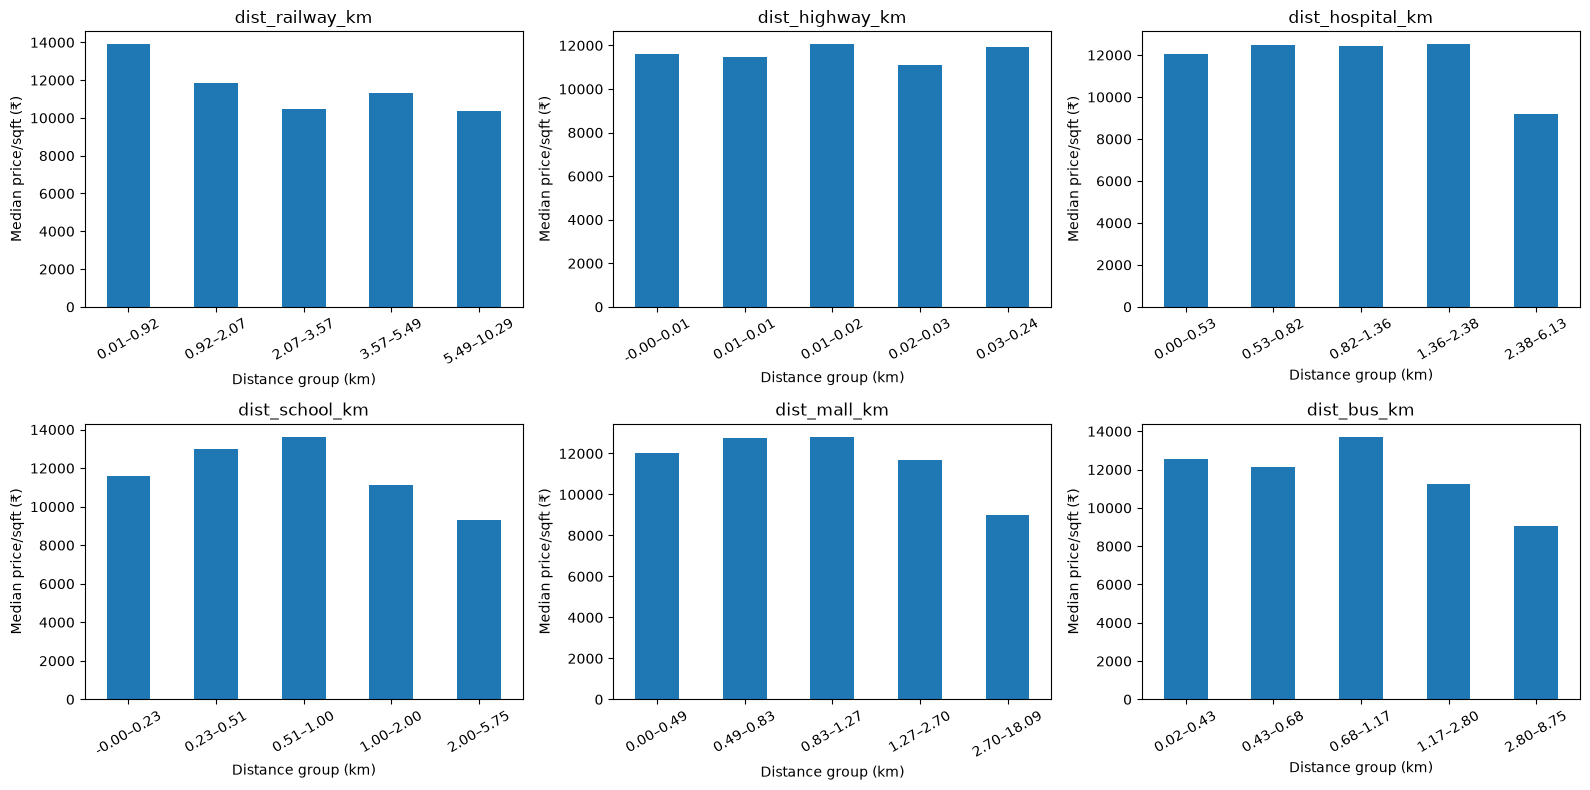

In [97]:

def binned_plot(col, ax):
    temp = data[[col, "price_per_sqft"]].replace(
        [np.inf, -np.inf], np.nan
    ).dropna()

    if len(temp) == 0 or temp[col].nunique() < 2:
        ax.set_title(f"{col}\nInsufficient variation")
        return

    temp["distance_group"] = pd.qcut(
        temp[col],
        q=5,
        duplicates="drop"
    )

    medians = temp.groupby(
        "distance_group",
        observed=True
    )["price_per_sqft"].median()

    labels = [
        f"{interval.left:.2f}–{interval.right:.2f}"
        for interval in medians.index
    ]

    medians.index = labels
    medians.plot(kind="bar", ax=ax)

    ax.set_title(col)
    ax.set_ylabel("Median price/sqft (₹)")
    ax.set_xlabel("Distance group (km)")
    ax.tick_params(axis="x", rotation=30)


cols = [
    "dist_railway_km",
    "dist_highway_km",
    "dist_hospital_km",
    "dist_school_km",
    "dist_mall_km",
    "dist_bus_km"
]

cols = [c for c in cols if c in data.columns]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.ravel()

for ax, col in zip(axes, cols):
    binned_plot(col, ax)

# Hide unused axes if fewer than six features exist
for ax in axes[len(cols):]:
    ax.set_visible(False)

plt.tight_layout()

os.makedirs("../reports/figures", exist_ok=True)

plt.savefig(
    "../reports/figures/07_distance_vs_price.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()



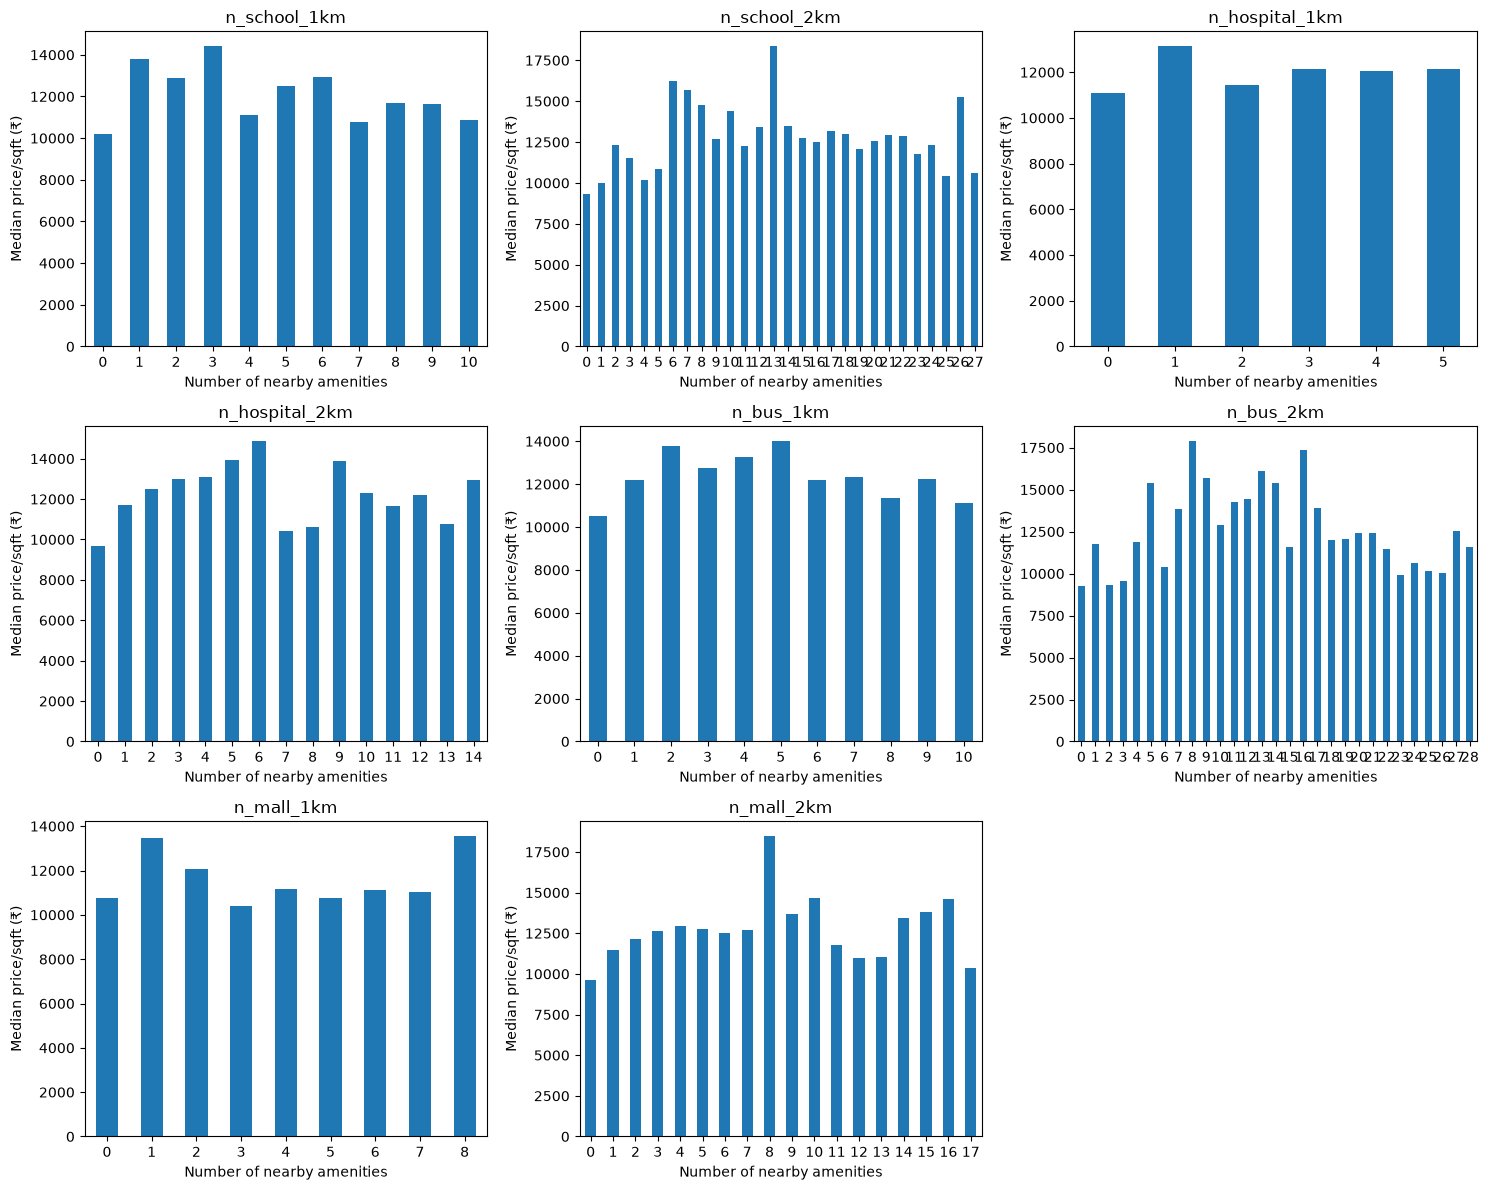

In [98]:

count_cols = [
    c for c in data.columns
    if c.startswith("n_") and c.endswith(("1km", "2km"))
]

if count_cols:
    ncols = 3
    nrows = int(np.ceil(len(count_cols) / ncols))

    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(15, 4 * nrows)
    )

    axes = np.array(axes).reshape(-1)

    for ax, col in zip(axes, count_cols):
        temp = data[[col, "price_per_sqft"]].dropna()

        summary = temp.groupby(col)["price_per_sqft"].median()

        # Limit the plot to count values covering most observations
        max_count = temp[col].quantile(0.95)
        summary = summary.loc[summary.index <= max_count]

        summary.plot(kind="bar", ax=ax)
        ax.set_title(col)
        ax.set_xlabel("Number of nearby amenities")
        ax.set_ylabel("Median price/sqft (₹)")
        ax.tick_params(axis="x", rotation=0)

    for ax in axes[len(count_cols):]:
        ax.set_visible(False)

    plt.tight_layout()
    plt.savefig(
        "../reports/figures/08_amenity_counts_vs_price.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()
else:
    print("No nearby amenity count columns found.")



In [99]:
# Save numeric p-values in the CSV, rather than formatted strings
corr_export = corr_table.copy()

corr_export["p_value"] = pd.to_numeric(
    corr_export["p_value"],
    errors="coerce"
)

corr_export.to_csv(
    "../reports/location_price_correlations.csv",
    index=False
)

print("Saved correlation table to:")
print(os.path.abspath("../reports/location_price_correlations.csv"))

print("\nSaved figures:")
print(os.path.abspath("../reports/figures/07_distance_vs_price.png"))
print(os.path.abspath("../reports/figures/08_amenity_counts_vs_price.png"))


Saved correlation table to:
d:\real-estate-price-prediction\reports\location_price_correlations.csv

Saved figures:
d:\real-estate-price-prediction\reports\figures\07_distance_vs_price.png
d:\real-estate-price-prediction\reports\figures\08_amenity_counts_vs_price.png


In [100]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("../reports/figures", exist_ok=True)



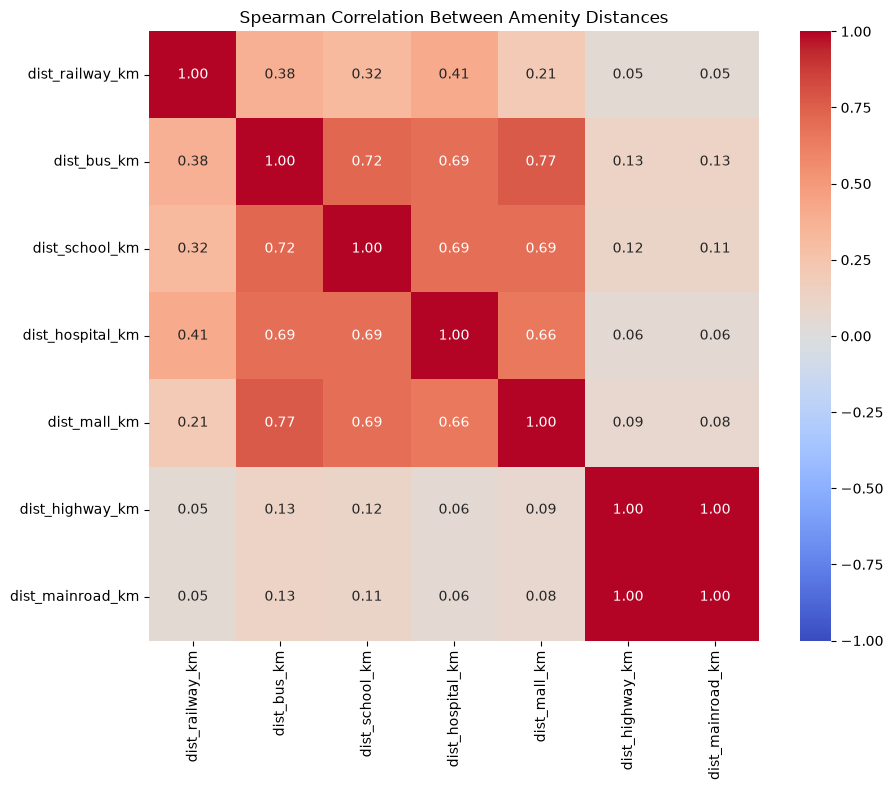

In [101]:

# Select distance features only
dist_df = feats.filter(like="dist_")

# Calculate correlations
dist_corr = dist_df.corr(method="spearman")

# Plot heatmap
plt.figure(figsize=(10, 8))

sns.heatmap(
    dist_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Spearman Correlation Between Amenity Distances")
plt.tight_layout()

plt.savefig(
    "../reports/figures/08_distance_correlations.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


In [102]:

# Get the upper triangle to avoid duplicate pairs
upper = dist_corr.where(
    np.triu(np.ones(dist_corr.shape), k=1).astype(bool)
)

high_corr_pairs = (
    upper.stack()
    .reset_index()
)

high_corr_pairs.columns = ["feature_1", "feature_2", "correlation"]

high_corr_pairs = high_corr_pairs[
    high_corr_pairs["correlation"].abs() >= 0.70
].sort_values(
    "correlation",
    key=lambda s: s.abs(),
    ascending=False
)

print("Highly correlated distance pairs (|rho| >= 0.70):")

if high_corr_pairs.empty:
    print("No distance-feature pairs meet this threshold.")
else:
    display(high_corr_pairs.round(3))



Highly correlated distance pairs (|rho| >= 0.70):


,feature_1,feature_2,correlation
41,dist_highway_km,dist_mainroad_km,0.999
11,dist_bus_km,dist_mall_km,0.773
9,dist_bus_km,dist_school_km,0.724


In [103]:

feature_check = pd.DataFrame({
    "feature": feats.columns.drop("prop_id"),
    "unique_values": [
        feats[c].nunique(dropna=True)
        for c in feats.columns
        if c != "prop_id"
    ],
    "missing_values": [
        feats[c].isna().sum()
        for c in feats.columns
        if c != "prop_id"
    ],
    "zero_values": [
        (feats[c] == 0).sum()
        for c in feats.columns
        if c != "prop_id"
    ]
})

display(feature_check)



,feature,unique_values,missing_values,zero_values
0,dist_railway_km,1137,0,0
1,dist_bus_km,1137,0,0
2,dist_school_km,1132,0,137
3,dist_hospital_km,1137,0,0
4,dist_mall_km,1137,0,0
5,dist_highway_km,1137,0,0
6,dist_mainroad_km,1137,0,0
7,n_school_1km,17,0,3081
8,n_school_2km,37,0,1537
9,n_hospital_1km,12,0,4045


In [104]:

dist_corr.to_csv(
    "../reports/distance_correlations.csv",
    index=True
)

print("Saved heatmap:")
print(os.path.abspath("../reports/figures/08_distance_correlations.png"))

print("\nSaved correlation matrix:")
print(os.path.abspath("../reports/distance_correlations.csv"))


Saved heatmap:
d:\real-estate-price-prediction\reports\figures\08_distance_correlations.png

Saved correlation matrix:
d:\real-estate-price-prediction\reports\distance_correlations.csv


In [105]:

import os
import pandas as pd

# Ensure output directory exists
os.makedirs("../data/processed", exist_ok=True)

# Save location features, retaining prop_id as the join key
feats.to_csv(
    "../data/processed/location_features.csv",
    index=False
)

# Save updated dataset without price_per_sqft
data.drop(
    columns=["price_per_sqft"],
    errors="ignore"
).to_csv(
    "../data/processed/clean_v3_location.csv",
    index=False
)

print("Location features saved:", feats.shape)
print("Updated modeling dataset saved:", data.drop(
    columns=["price_per_sqft"],
    errors="ignore"
).shape)



Location features saved: (7457, 16)
Updated modeling dataset saved: (7457, 34)


In [106]:

# Reload saved files
saved_feats = pd.read_csv("../data/processed/location_features.csv")
saved_data = pd.read_csv("../data/processed/clean_v3_location.csv")

print("Location features:")
print("Shape:", saved_feats.shape)
print("Duplicate prop_id:", saved_feats["prop_id"].duplicated().sum())
print("Missing prop_id:", saved_feats["prop_id"].isna().sum())

print("\nUpdated modeling dataset:")
print("Shape:", saved_data.shape)
print("Contains price_per_sqft:", "price_per_sqft" in saved_data.columns)
print("Contains price_lakhs:", "price_lakhs" in saved_data.columns)

# Confirm the location-feature IDs match the merged dataset
print(
    "\nSame number of rows in feats and saved location features:",
    len(feats) == len(saved_feats)
)

display(saved_feats.head())
display(saved_data.head())



Location features:
Shape: (7457, 16)
Duplicate prop_id: 0
Missing prop_id: 0

Updated modeling dataset:
Shape: (7457, 34)
Contains price_per_sqft: False
Contains price_lakhs: True

Same number of rows in feats and saved location features: True


,prop_id,dist_railway_km,dist_bus_km,dist_school_km,dist_hospital_km,dist_mall_km,dist_highway_km,dist_mainroad_km,n_school_1km,n_school_2km,n_hospital_1km,n_hospital_2km,n_bus_1km,n_bus_2km,n_mall_1km,n_mall_2km
0,O71585872,4.718649,5.866253,4.760367,2.511597,4.430818,0.006102,0.006102,0,0,0,0,0,0,0,0
1,T71585466,5.834544,7.903888,2.774529,2.715225,5.692716,0.005423,0.005423,0,0,0,0,0,0,0,0
2,I71493958,1.861994,1.937073,1.686636,1.559152,1.261223,0.004921,0.004921,0,4,0,1,0,1,0,3
3,X71361930,1.569207,1.464931,1.510960,1.772932,1.371881,0.022995,0.022995,0,3,0,3,0,4,0,2
4,N71483500,6.086466,1.605551,0.582855,1.998448,1.723163,0.044808,0.044808,3,3,0,0,0,8,0,1


,prop_id,latitude,longitude,property_type,owntype,bedroom_num,bathroom_num,balcony_num,furnish,facing,...,dist_highway_km,dist_mainroad_km,n_school_1km,n_school_2km,n_hospital_1km,n_hospital_2km,n_bus_1km,n_bus_2km,n_mall_1km,n_mall_2km
0,O71585872,28.406534,76.962792,Residential Apartment,1,4.0,4,4.0,4,1,...,0.006102,0.006102,0,0,0,0,0,0,0,0
1,T71585466,28.388907,76.951328,Residential Apartment,1,4.0,4,3.0,4,1,...,0.005423,0.005423,0,0,0,0,0,0,0,0
2,I71493958,28.518677,77.015115,Residential Apartment,1,3.0,3,3.0,4,0,...,0.004921,0.004921,0,4,0,1,0,1,0,3
3,X71361930,28.478440,76.986110,Residential Apartment,1,3.0,4,4.0,4,2,...,0.022995,0.022995,0,3,0,3,0,4,0,2
4,N71483500,28.416400,77.012620,Residential Apartment,1,2.0,2,3.0,2,3,...,0.044808,0.044808,3,3,0,0,0,8,0,1


In [107]:

from pathlib import Path

external_dir = Path("../data/external")

print("External directory:", external_dir.resolve())

for file in sorted(external_dir.iterdir()):
    if file.is_file():
        size_mb = file.stat().st_size / (1024 * 1024)
        print(f"{file.name:35} {size_mb:10.2f} MB")



External directory: D:\real-estate-price-prediction\data\external
bus.gpkg                                  0.39 MB
gurgaon_bbox.json                         0.00 MB
highway.gpkg                             27.95 MB
hospital.gpkg                             0.20 MB
india-latest.osm.pbf                    213.71 MB
mainroad.gpkg                            28.13 MB
mall.gpkg                                 0.14 MB
railway.gpkg                              0.14 MB
school.gpkg                               0.23 MB


In [1]:
import pandas as pd

df = pd.read_csv("data/processed/model_data.csv")

for col in ["owntype", "furnish", "facing", "age"]:
    print(f"\n{col}")
    print(df[col].value_counts().sort_index())

FileNotFoundError: [Errno 2] No such file or directory: 'data/processed/model_data.csv'

In [2]:
import os

print(os.getcwd())


d:\real-estate-price-prediction\notebooks


In [3]:
import pandas as pd

df = pd.read_csv("../data/processed/model_data.csv")

for col in ["owntype", "furnish", "facing", "age"]:
    print(f"\n{col}")
    print(df[col].value_counts().sort_index())


owntype
owntype
1    7375
2      43
3      31
4       8
Name: count, dtype: int64

furnish
furnish
0     244
1     509
2     940
4    5764
Name: count, dtype: int64

facing
facing
0     833
1    1045
2     181
3    1728
4     468
5    2500
6     269
7     262
8     171
Name: count, dtype: int64

age
age
0       1
1    2447
2    1157
3     538
5    1255
6    2059
Name: count, dtype: int64


In [4]:
import pandas as pd

df_raw = pd.read_csv("../data/raw/housing_raw.csv")

print("Columns related to our four features:")

for col in df_raw.columns:
    if any(word in col.lower() for word in
           ["own", "furnish", "facing", "age"]):
        print("\nColumn:", col)
        print("Unique values:", df_raw[col].dropna().unique()[:30])

C:\Users\hp\AppData\Local\Temp\ipykernel_21236\2840122691.py:3: DtypeWarning: Columns (66: FURNISHING_ATTRIBUTES) have mixed types. Specify dtype option on import or set low_memory=False.
  df_raw = pd.read_csv("../data/raw/housing_raw.csv")


Columns related to our four features:

Column: OWNTYPE
Unique values: [1 0 4 3 2]

Column: FURNISH
Unique values: [4 1 2 0]

Column: FACING
Unique values: [1 4 0 6 2 8 3 5 7]

Column: AGE
Unique values: [2 1 6 0 5 3]

Column: BROKERAGE
Unique values: [2.630e+05 1.000e+00 4.200e+04 7.500e+05 3.500e+04 3.500e+05 4.950e+05
 1.150e+05 2.100e+05 6.300e+05 0.000e+00 6.000e+05 4.250e+05 3.000e+05
 1.500e+05 2.175e+04 6.500e+04 1.200e+05 1.000e+05 2.250e+04 8.700e+04
 3.750e+04 7.500e+04 5.000e+05 3.000e+04 4.000e+04 1.025e+06 1.500e+01
 5.000e+01 1.500e+04]

Column: PROPERTY_IMAGES
Unique values: <ArrowStringArray>
[                                                                                                                                                                                                                                                                                                                                                                                               